# Определение стоимости автомобилей

<div style="background-color: white; border: 1.5px solid black; border-radius: 1px; padding: 15px 25px; display: inline-block; color: black;">
    
## <span style="color:yellowgreen"> Описание проекта

---
    
**Заказчик:** Сервис по продаже автомобилей с пробегом `«Не бит, не крашен»`.

**Цель:** Разработать модель для определения рыночной стоимости автомобиля на основе его технических характеристик, комплектации и исторических данных о ценах.

**Задачи:**

<span style="color:yellowgreen">

**1.** <span style="color:black">Провести исследовательский анализ данных, обработать пропуски, аномалии и подготовить признаки для обучения моделей;

**2.** <span style="color:black">Подготовить выборки для обучения моделей;

**3.** <span style="color:black">Обучить несколько моделей:

- <span style="color:black">RANDOM FOREST
- <span style="color:black">LIGHTGBM


**4.** <span style="color:black">Провести подбор гиперпараметров для каждой модели

**5.** <span style="color:black">Сравнить модели по трём ключевым критериям:

- <span style="color:black">качество модели (RMSE)
- <span style="color:black">время обучения модели
- <span style="color:black">время предсказания модели

**6.** <span style="color:black">Выбрать лучшую модель, проверить её качество на тестовой выборке и сделать выводы

---

<span style="color:black">

**Критерии успеха:**

- `RMSE < 2500 евро`

- `Баланс между скоростью работы и точностью предсказаний`

---

ОПИСАНИЕ ДАННЫХ

<span style="color:yellowgreen">
    
- <span style="color:black"> `DateCrawled` — дата скачивания анкеты из базы;
- <span style="color:black"> `VehicleType` — тип автомобильного кузова;
- <span style="color:black"> `RegistrationYear` — год регистрации автомобиля;
- <span style="color:black"> `Gearbox` — тип коробки передач;
- <span style="color:black"> `Power` — мощность (л. с.);
- <span style="color:black"> `Model` — модель автомобиля;
- <span style="color:black"> `Kilometer` — пробег (км);
- <span style="color:black"> `RegistrationMonth` — месяц регистрации автомобиля;
- <span style="color:black"> `FuelType` — тип топлива;
- <span style="color:black"> `Brand` — марка автомобиля;
- <span style="color:black"> `Repaired` — была машина в ремонте или нет;
- <span style="color:black"> `DateCreated` — дата создания анкеты;
- <span style="color:black"> `NumberOfPictures` — количество фотографий автомобиля;
- <span style="color:black"> `PostalCode` — почтовый индекс владельца анкеты (пользователя);
- <span style="color:black"> `LastSeen` — дата последней активности пользователя.

Целевой признак:

- <span style="color:black"> `Price` — цена автомобиля (евро)

---

</div>

<div style="border-left: 3px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Импорты

In [1]:
!pip install lightgbm -q
!pip install category_encoders -q


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\dns\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\dns\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
# Основные библиотеки
import pandas as pd
import numpy as np
import time
import warnings
import itertools
from collections import defaultdict

# Загрузка данных
import os
import requests
from io import BytesIO

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Статистика и корреляция
from phik import phik_matrix

# Подготовка данных и Обучение моделей
from category_encoders import TargetEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb

# Настройки
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
TEST_SIZE = 0.25

## <span style="color:yellowgreen"> Загрузка и изучение данных

#### Функция. Импорт таблицы

In [3]:
def import_google_sheet(spreadsheet_id, sheet_name=None, local_paths=None):
    '''
    Импортируем Google-таблицу в pandas DataFrame с fallback на локальные файлы
    '''
    
    # Сначала пробуем локальные файлы
    if local_paths:
        for path in local_paths:
            if os.path.exists(path):
                print(f"Загружаем из локального файла: {path}")
                return pd.read_csv(path)
    
    # Если локальных файлов нет, грузим из Google Sheets
    if sheet_name:
        url = f'https://docs.google.com/spreadsheets/d/{spreadsheet_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}'
    else:
        url = f'https://docs.google.com/spreadsheets/d/{spreadsheet_id}/export?format=csv'
    
    print(f"Загружаем из Google Sheets: {url}")
    
    r = requests.get(url)
    r.raise_for_status()
    
    return pd.read_csv(BytesIO(r.content))

In [4]:
df = import_google_sheet(
                          spreadsheet_id='1sv_QvYYvJFnI0MUZpXX4-BJdmIVjff_tjtcLETTm6i0',  # ID Google таблицы с autos
                          local_paths=[
                                       '/data/autos.csv',  # серверный путь
                                       'C:/projects/data/autos.csv', # Windows путь
                                       './data/autos.csv'  # локальный путь
                                       ]
                                        )

Загружаем из Google Sheets: https://docs.google.com/spreadsheets/d/1sv_QvYYvJFnI0MUZpXX4-BJdmIVjff_tjtcLETTm6i0/export?format=csv


#### Функция. Пропущенные значения

In [5]:
def get_missing_info(df):
    """Возвращает DataFrame с информацией о пропущенных значениях"""
    missing_values = df.isnull().sum()
    total_rows = df.shape[0]
    columns_with_missing = missing_values[missing_values > 0]
    
    if len(columns_with_missing) == 0:
        return None
    
    missing_df = pd.DataFrame({
                               'Столбец': columns_with_missing.index,
                               'Кол-во пропусков': columns_with_missing.values,
                               '% пропусков': (columns_with_missing.values / total_rows * 100).round(2)
                              })
    return missing_df

#### Функция. Общая информация и Первые строки

In [6]:
def head_and_info_display(df, n=5, show_shape=True, show_dtypes=True):
    '''
    Параметры:
    df - DataFrame для анализа
    n - Количество строк
    '''
    print('~' * 23)
    print('ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ')
    print('~' * 23)
    
    # 1. Размер данных
    if show_shape:
        print(f'Форма данных: {df.shape[0]} строк, {df.shape[1]} столбцов')

    # 2. Названия столбцов
    print(f"\nНАЗВАНИЯ СТОЛБЦОВ ({len(df.columns)} шт.):")
    print("-" * 30)
    for i, col in enumerate(df.columns, 1):
        print(f"{i:2}. {col}")
    
    # 3. Первые n строк
    print(f"\nПервые {n} строк:")
    print("-" * 15)
    display(df.head(n))
    
    # 4. Общая информация
    if show_dtypes:
        print(f"\nОбщая информация:")
        print("-" * 17)
        df.info()
    
    # 5. Пропущенные значения (используем отдельную функцию get_missing_info)
    print(f"\nПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:")
    print("-" * 30)
    
    missing_df = get_missing_info(df)
    
    if missing_df is None:
        print('Пропущенных значений нет')
    else:
        print(f'Столбцы с пропущенными значениями ({len(missing_df)} из {df.shape[1]}):')
        display(missing_df)
        
        total_missing = df.isnull().sum().sum()
        total_rows = df.shape[0]
        print(f'Всего пропусков в датафрейме: {total_missing}')
        print(f'Доля пропущенных значений: {(total_missing / (total_rows * df.shape[1]) * 100).round(2)}%')
       
    # 6. Дубликаты строк
    print(f'\nПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:')
    print("-" * 20)
    duplicates_count = df.duplicated().sum()
    total_rows = df.shape[0]
    if duplicates_count == 0:
        print('Дубликатов строк нет')
    else:
        print(f'Найдено {duplicates_count} дубликатов строк ({duplicates_count/total_rows*100:.2f}% данных)') 

In [7]:
# Выведем информацию о датафрейме df
head_and_info_display(df)

~~~~~~~~~~~~~~~~~~~~~~~
ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ
~~~~~~~~~~~~~~~~~~~~~~~
Форма данных: 354369 строк, 16 столбцов

НАЗВАНИЯ СТОЛБЦОВ (16 шт.):
------------------------------
 1. DateCrawled
 2. Price
 3. VehicleType
 4. RegistrationYear
 5. Gearbox
 6. Power
 7. Model
 8. Kilometer
 9. RegistrationMonth
10. FuelType
11. Brand
12. Repaired
13. DateCreated
14. NumberOfPictures
15. PostalCode
16. LastSeen

Первые 5 строк:
---------------


,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 0:00:00,0,70435,2016-04-07 3:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 0:00:00,0,66954,2016-04-07 1:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 0:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 0:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 0:00:00,0,60437,2016-04-06 10:17:21



Общая информация:
-----------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  Repaired           283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-n

,Столбец,Кол-во пропусков,% пропусков
0,VehicleType,37490,10.58
1,Gearbox,19833,5.60
2,Model,19705,5.56
3,FuelType,32895,9.28
4,Repaired,71154,20.08


Всего пропусков в датафрейме: 181077
Доля пропущенных значений: 3.19%

ПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:
--------------------
Найдено 4 дубликатов строк (0.00% данных)


In [8]:
# Дропаем дубликаты
df = df.drop_duplicates()
df.shape #Проверяем

(354365, 16)

<div style="background-color: white; border: 2px solid black; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">

<div style="border-left: 3px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 


### в ы в о д

---
<span style="color:yellowgreen">
    
В ДАННОМ РАЗДЕЛЕ МЫ ЗНАКОМИЛИСЬ С ДАННЫМИ И ПЕРВИЧНО ИХ ОЦЕНИЛИ.
    
**1.** <span style="color:black">В 5 из 16 столбцов есть пропущенные значения:

- `Средний % пропусков: 3.19%`,
- `Всего пропусков в датафрейме: 181077`.
  
**2.** <span style="color:black">Обнаружены явные дубликаты (`4 строки`) - удалили;

**3.** <span style="color:black">В таблице стало после удаления дубликатов `354365 строк` и `16 столбцов`.

---

ДАЛЕЕ

<span style="color:black"> *Проведем подготовку данных:*

- <span style="color:black"> Изучим данные ближе: `Заполним пропущенные значения и обработаем аномалии в столбцах. Удалим неинформативные признаки.`
- <span style="color:black"> А так же `исправим названия столбцов и обработаем неявные дубликаты.`


## <span style="color:yellowgreen">Подготовка данных

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Изменение названий признаков

In [9]:
# Меняем названия колонок
df.columns = df.columns.str.replace(r'(?<!^)(?=[A-Z])', '_', regex=True).str.lower()
print(df.columns) # Проверяем

Index(['date_crawled', 'price', 'vehicle_type', 'registration_year', 'gearbox',
       'power', 'model', 'kilometer', 'registration_month', 'fuel_type',
       'brand', 'repaired', 'date_created', 'number_of_pictures',
       'postal_code', 'last_seen'],
      dtype='object')


#### Функция. Уникальные значения

In [10]:
def show_unique_for_columns(df, columns):
    """Выводит уникальные значения только для указанных столбцов"""
    
    for col in columns:
        if col in df.columns:
            unique_vals = df[col].unique()
            print(f"\n{col} ({df[col].dtype})")
            print("-" * 120)
            print(f"Уникальных значений: {len(unique_vals)}")
            print(f"Значения: {list(unique_vals)}")
        else:
            print(f"\n{col} - столбец не найден в датафрейме")

# Использование
columns_to_show = ['brand', 'model', 'vehicle_type', 'gearbox', 'fuel_type', 'repaired', 'number_of_pictures']
show_unique_for_columns(df, columns_to_show)


brand (object)
------------------------------------------------------------------------------------------------------------------------
Уникальных значений: 40
Значения: ['volkswagen', 'audi', 'jeep', 'skoda', 'bmw', 'peugeot', 'ford', 'mazda', 'nissan', 'renault', 'mercedes_benz', 'opel', 'seat', 'citroen', 'honda', 'fiat', 'mini', 'smart', 'hyundai', 'sonstige_autos', 'alfa_romeo', 'subaru', 'volvo', 'mitsubishi', 'kia', 'suzuki', 'lancia', 'toyota', 'chevrolet', 'dacia', 'daihatsu', 'trabant', 'saab', 'chrysler', 'jaguar', 'daewoo', 'porsche', 'rover', 'land_rover', 'lada']

model (object)
------------------------------------------------------------------------------------------------------------------------
Уникальных значений: 251
Значения: ['golf', nan, 'grand', 'fabia', '3er', '2_reihe', 'other', 'c_max', '3_reihe', 'passat', 'navara', 'ka', 'polo', 'twingo', 'a_klasse', 'scirocco', '5er', 'meriva', 'arosa', 'c4', 'civic', 'transporter', 'punto', 'e_klasse', 'clio', 'kadett', '

In [11]:
# Преобразуем столбцы в datetime формат
df['date_crawled'] = pd.to_datetime(df['date_crawled'])
df['date_created'] = pd.to_datetime(df['date_created'])
df['last_seen'] = pd.to_datetime(df['last_seen'])

# Теперь можно использовать .dt
print('Период скачивания объявлений:   ', df['date_crawled'].dt.date.min(), '-', df['date_crawled'].dt.date.max())
print('Период публикаций объявлений:   ', df['date_created'].dt.date.min(), '-', df['date_created'].dt.date.max())
print('Период активности пользователей:', df['last_seen'].dt.date.min(), '-', df['last_seen'].dt.date.max())

# Создаем признак года публикации
df['year_created'] = df['date_created'].dt.year

# Выводим количество объявлений по годам
display(df.groupby('year_created')['brand'].count().to_frame().rename(columns={'brand': 'count'}))

Период скачивания объявлений:    2016-03-05 - 2016-04-07
Период публикаций объявлений:    2014-03-10 - 2016-04-07
Период активности пользователей: 2016-03-05 - 2016-04-07


,count
year_created,
2014,1
2015,25
2016,354339


<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**1. Период скачивания объявлений: `2016-03-05 — 2016-04-07`** [Даты, когда система собирала (скачивала) объявления с сайта]

- Данные собирались в течение ~1 месяца (март — начало апреля 2016)
- Это период сбора данных, а не период продажи автомобилей
- Все объявления актуальны на март-апрель 2016 года

**2. Период публикаций объявлений: `2014-03-10 — 2016-04-07`** [Даты, когда пользователи создали объявления]

- Самые старые объявления созданы в 2014 году (1 объявление)
- Основная масса объявлений создана в 2016 году
- Некоторые объявления "висели" на сайте очень долго (до 2 лет)

**3. Период активности пользователей: 2016-03-05 — 2016-04-07** [Даты последней активности пользователей (просмотры, обновления)]

- Пользователи были активны в тот же период, что и сбор данных
- Все объявления актуальны на момент скачивания

**4. Распределение по году публикации**

- Подавляющее большинство объявлений (99.99%) созданы в 2016 году
- Объявления 2014-2015 годов — единичные случаи (вероятно, не проданные авто, которые долго висели)

---

<div style="border-left: 3px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 


- Данные собраны за 1 месяц 2016 года
- Почти все авто продавались в 2016 году
- Единичные объявления 2014-2015 --> Можно удалить как аномалии или оставить (не повлияют)

Можно удалить технические даты не влияют на цену:

- `date_crawled`
- `registration_month`	[Избыточен. Есть `registration_year`]
- `date_created`
- `year_created`
- `number_of_pictures`	[Все значения равны 0]
- `last_seen`

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Удаление неинформативных признаков


In [12]:
# Удаление неинформативных признаков
columns_to_drop = ['date_crawled', 'last_seen','number_of_pictures', 'registration_month', 'date_created', 'year_created']
df.drop(columns=columns_to_drop, inplace=True)

print(f'Оставшиеся столбцы: {list(df.columns)}')

Оставшиеся столбцы: ['price', 'vehicle_type', 'registration_year', 'gearbox', 'power', 'model', 'kilometer', 'fuel_type', 'brand', 'repaired', 'postal_code']


<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Обработка неявных дубликатов


<span style="color:yellowgreen">
    
- <span style="color:black"> П Р И З Н А К:  `model`

In [13]:
# Исправление неявных дубликатов моделей
model_fixes = {
               # BMW
               '1er': '1_series', '1_reihe': '1_series', 'serie_1': '1_series',
               '3er': '3_series', '3_reihe': '3_series', 'serie_3': '3_series',
               '5er': '5_series', '5_reihe': '5_series', 'serie_5': '5_series',
    
                # Mercedes
                'a_klasse': 'a_class', 'b_klasse': 'b_class', 'c_klasse': 'c_class',
                'e_klasse': 'e_class', 's_klasse': 's_class', 'm_klasse': 'm_class',
    
                # Land Rover
                'rangerover': 'range_rover',
    
                # Другие
                'other': 'other_model'
               }

# Сохраняем количество уникальных моделей ДО
before_count = df['model'].nunique()

# Замена (преобразуем в object, заменяем, возвращаем category)
df['model'] = df['model'].replace(model_fixes)

print(f"Уникальных моделей ДО: {before_count}")
print(f"Уникальных моделей ПОСЛЕ: {df['model'].nunique()}")

Уникальных моделей ДО: 250
Уникальных моделей ПОСЛЕ: 244


<span style="color:yellowgreen">
    
- <span style="color:black">П Р И З Н А К:  `fuel_type`

In [14]:
# Объединим gasoline c petrol
before = df['fuel_type'].value_counts()

# Временно преобразуем в строку, заменяем, возвращаем category
df['fuel_type'] = df['fuel_type'].replace('gasoline', 'petrol')

after = df['fuel_type'].value_counts()

# проверяем
pd.DataFrame({'ДО': before, 'ПОСЛЕ': after}).fillna('-').loc[['petrol', 'gasoline', 'lpg', 'cng', 'hybrid', 'electric', 'other']]

,ДО,ПОСЛЕ
fuel_type,,
petrol,216349,315068.0
gasoline,98719,-
lpg,5310,5310.0
cng,565,565.0
hybrid,233,233.0
electric,90,90.0
other,204,204.0


<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Обработка пропущенных значений

<span style="color:yellowgreen">
    
- <span style="color:black"> `Заполниние/удаление`


<span style="color:yellowgreen">
    
**ЗАПОЛНЕНИЕ**

- <span style="color:black"> `vehicle_type`
- <span style="color:black">`gearbox`
- <span style="color:black">`model`
- <span style="color:black">`fuel_type`

---

- Один эталон, строится только по тренировочной выборке [ Тестовые данные не влияют на заполнение]
- Оба набора (train и test) заполняются по одному и тому же эталону [Модель честно тестируется на "невидимых" данных]
- Тестовая выборка никогда не используется для построения эталона [Чтобы модель не "подглядывала" в будущее, не было завышенной оценки качества]

<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**1. Определение приоритетов признаков, создание списка заполняемых колонок.**

<span style="color:yellowgreen">

- <span style="color:black">Приоритеты позволяют алгоритму выбирать наиболее значимые комбинации признаков
- <span style="color:black">`fill_columns` определяет, какие именно пропуски мы будем заполнять

In [15]:
# Создаем списки признаков 111111
fill_columns = ['model', 'vehicle_type', 'fuel_type', 'gearbox']

In [16]:
# Приоритет признаков (чем выше число, тем важнее)
priority = {
            'brand': 100,      # Самый важный - бренд определяет многое
            'power': 90,       # Мощность часто уникальна для модели
            'vehicle_type': 80,# Тип кузова важен для идентификации
            'model': 70,       # Модель - ключевой признак
            'gearbox': 60,     # Коробка передач
            'fuel_type': 50    # Тип топлива - наименее значимый
            }

In [17]:
# ИСПРАВЛЕНО: сплит выполняется ДО любого заполнения пропусков
# Создаем X и y
X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
                                                    X, y, 
                                                    test_size=TEST_SIZE, random_state=RANDOM_STATE
                                                    #,stratify=df['repaired']  #сохраняем пропорции
                                                    )


print(f'Размерность X_train: {X_train.shape}')
print(f'Размерность X_test: {X_test.shape}')

Размерность X_train: (265773, 10)
Размерность X_test: (88592, 10)


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**2. Создание эталонной таблицы с уникальными автомобилями без пропусков и дубликатов.**

<span style="color:yellowgreen">

- <span style="color:black">Эталон содержит только достоверные данные для поиска совпадений (строится на тренировочных данных во избежании утечки данных при обучении моделей)
- <span style="color:black">Удаление дубликатов ускоряет поиск и повышает точность

In [18]:
autos_full_train = X_train[['brand', 'model', 'vehicle_type', 
                            'gearbox', 'power', 'fuel_type']].dropna().drop_duplicates()

print(f"Исходный датафрейм TRAIN : {len(X_train)} строк")
print(f"Эталонная таблица [без пропусков и дубликатов]: {len(autos_full_train)} строк")
print(f"Уникальных комбинаций автомобилей: {len(autos_full_train)}")

# Проверка
print("\nПРИМЕРЫ ЭТАЛОННЫХ ЗАПИСЕЙ:")
display(autos_full_train.head(3))

Исходный датафрейм TRAIN : 265773 строк
Эталонная таблица [без пропусков и дубликатов]: 21258 строк
Уникальных комбинаций автомобилей: 21258

ПРИМЕРЫ ЭТАЛОННЫХ ЗАПИСЕЙ:


,brand,model,vehicle_type,gearbox,power,fuel_type
58749,mercedes_benz,slk,convertible,auto,163,petrol
156475,volkswagen,polo,coupe,manual,54,petrol
348721,renault,scenic,bus,auto,135,petrol


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**3. Создание словаря, где ключ - комбинация признаков, а значения - соответствующие строки из эталона.**

<span style="color:yellowgreen">
    
- <span style="color:black"> Ускорение работы

In [19]:
%%time
autos_indexed = {}
for combo_size in [2, 3, 4, 5]:
    autos_indexed[combo_size] = defaultdict(list)
    
    for idx, row in autos_full_train.iterrows():
        all_cols = ['brand', 'power', 'model', 'vehicle_type', 'gearbox', 'fuel_type']
        for combo in itertools.combinations(all_cols, combo_size):
            key = tuple((col, row[col]) for col in sorted(combo))
            autos_indexed[combo_size][key].append(row.to_dict())

# Проверка
print(f"Созданы индексы для комбинаций размером 2, 3, 4, 5")
print(f"Комбинаций размера 2: {len(autos_indexed[2])}")
print(f"Комбинаций размера 3: {len(autos_indexed[3])}")
print(f"Комбинаций размера 4: {len(autos_indexed[4])}")
print(f"Комбинаций размера 5: {len(autos_indexed[5])}")

Созданы индексы для комбинаций размером 2, 3, 4, 5
Комбинаций размера 2: 18739
Комбинаций размера 3: 78324
Комбинаций размера 4: 125596
Комбинаций размера 5: 86344
CPU times: total: 1min 5s
Wall time: 1min 9s


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**4. Выявление строк с пропусками и сохранение их исходных значений.**

<span style="color:yellowgreen">
    
- <span style="color:black">Сохраняем исходные значения для защиты от перезаписи
- <span style="color:black">Определяем объем работы для оценки времени

In [20]:
# ---------------------------ДЛЯ TRAIN----------------------------------
counters_train = {col: 0 for col in fill_columns}
nan_index_train = X_train[X_train[fill_columns].isna().any(axis=1)].index
failed_rows_train = []

# Сохраняем исходные значения для train
original_values_train = {}
for i in nan_index_train:
    original_values_train[i] = {col: X_train.loc[i, col] for col in fill_columns}

print(f"Всего строк с пропусками в train: {len(nan_index_train)}")

# Проверка пропусков в каждой колонке
print("\nПРОПУСКИ В TRAIN ДО ОБРАБОТКИ:")
get_missing_info(X_train)

Всего строк с пропусками в train: 52707

ПРОПУСКИ В TRAIN ДО ОБРАБОТКИ:


,Столбец,Кол-во пропусков,% пропусков
0,vehicle_type,28056,10.56
1,gearbox,14908,5.61
2,model,14720,5.54
3,fuel_type,24755,9.31
4,repaired,53297,20.05


In [21]:
# ------------------------ДЛЯ TEST--------------------------
counters_test = {col: 0 for col in fill_columns}
nan_index_test = X_test[X_test[fill_columns].isna().any(axis=1)].index
failed_rows_test = []

# Сохраняем исходные значения для TEST
original_values_test = {}
for i in nan_index_test:
    original_values_test[i] = {col: X_test.loc[i, col] for col in fill_columns}

print(f"Всего строк с пропусками в TEST: {len(nan_index_test)}")
print("\nПРОПУСКИ В TEST ДО ОБРАБОТКИ:")
get_missing_info(X_test)

Всего строк с пропусками в TEST: 17536

ПРОПУСКИ В TEST ДО ОБРАБОТКИ:


,Столбец,Кол-во пропусков,% пропусков
0,vehicle_type,9434,10.65
1,gearbox,4925,5.56
2,model,4985,5.63
3,fuel_type,8140,9.19
4,repaired,17857,20.16


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**5. Для каждой строки с пропусками ищем наиболее подходящее совпадение в эталоне и заполняем пропуски модальным значением.**

<span style="color:yellowgreen">

- <span style="color:black">Перебираем комбинации от больших к маленьким (максимум информации)
- <span style="color:black">Используем приоритеты для выбора лучшего совпаденния
- <span style="color:black">Мода - наиболее частовстречаемое значение

#### Функция. Заполнение пропусков

In [22]:
def fill_missing_data(data, original_values, counters, autos_indexed, name, save_example=False):
    """
    Заполняет пропуски в данных, используя autos_indexed
    """
    nan_idx = data[data[fill_columns].isna().any(axis=1)].index
    failed = []
    example_info = None
    
    for i in nan_idx:
        filled_params = {col: data.loc[i, col] for col in fill_columns + ['brand', 'power'] 
                         if pd.notna(data.loc[i, col])}
        
        missing_cols = [col for col in fill_columns if pd.isna(original_values[i][col])]
        
        if len(missing_cols) == 0 or len(filled_params) < 2:
            continue
        
        best_match, best_score = None, -1
        filled_cols = list(filled_params.keys())
        
        for r in range(min(5, len(filled_cols)), 1, -1):
            for combo in itertools.combinations(filled_cols, r):
                score = sum(priority.get(col, 0) for col in combo)
                if score <= best_score:
                    continue
                key = tuple((col, filled_params[col]) for col in sorted(combo))
                matches = autos_indexed.get(r, {}).get(key, [])
                if matches:
                    best_match = pd.DataFrame(matches)
                    best_score = score
                    if score >= 250:
                        break
            if best_match is not None:
                break
        
        if best_match is None:
            failed.append(i)
            continue
        
        # Сохраняем пример для демонстрации
        if save_example and example_info is None and len(missing_cols) >= 2:
            example_info = {
                'index': i,
                'brand': filled_params.get('brand'),
                'power': filled_params.get('power'),
                'before': {col: original_values[i][col] for col in missing_cols},
                'after': {col: best_match[col].mode().iloc[0] for col in missing_cols if len(best_match[col].mode()) > 0},
                'best_score': best_score
            }
        
        for col in missing_cols:
            if len(best_match[col].mode()) > 0:
                mode_value = best_match[col].mode().iloc[0]
                if pd.isna(original_values[i][col]):
                    data.loc[i, col] = mode_value
                    counters[col] += 1
        
        total = sum(counters.values())
        if total % 10000 == 0 and total > 0:
            print(f"заполнено пропусков в {name}: {total}")
    
    print(f"ОБРАБОТКА {name.upper()} ЗАВЕРШЕНА")
    return failed, example_info

- ЗАПОЛНЕНИЕ `TRAIN`

In [23]:
%%time

print(f"\nНАЧАЛО ОБРАБОТКИ TRAIN ({len(nan_index_train)} строк):")
failed_rows_train, example_info = fill_missing_data(X_train, original_values_train, counters_train, autos_indexed, "TRAIN", save_example=True)

# Сохраняем пример для вывода
if example_info:
    example_row_info = example_info


НАЧАЛО ОБРАБОТКИ TRAIN (52707 строк):
заполнено пропусков в TRAIN: 10000
заполнено пропусков в TRAIN: 20000
заполнено пропусков в TRAIN: 40000
заполнено пропусков в TRAIN: 50000
заполнено пропусков в TRAIN: 60000
ОБРАБОТКА TRAIN ЗАВЕРШЕНА
CPU times: total: 10min 35s
Wall time: 12min 58s


- ЗАПОЛНЕНИЕ `TEST`

In [24]:
%%time

print(f"\nНАЧАЛО ОБРАБОТКИ TEST ({len(nan_index_test)} строк):")
failed_rows_test, _ = fill_missing_data(X_test, original_values_test, counters_test, autos_indexed, "TEST", save_example=False)


НАЧАЛО ОБРАБОТКИ TEST (17536 строк):
заполнено пропусков в TEST: 10000
ОБРАБОТКА TEST ЗАВЕРШЕНА
CPU times: total: 1min 40s
Wall time: 1min 56s


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**6. Пример заполнения строки с несколькими строками**

<span style="color:yellowgreen">
    
- <span style="color:black">Позволяет отслеживать корректность заполнения

In [26]:
if example_info:
    print(f"\nИндекс строки: {example_info['index']}")
    print(f"Бренд: {example_info['brand']}, Мощность: {example_info['power']} л.с.")
    print(f"\nНайдено совпадение с оценкой: {example_info['best_score']}")
    print("\nЗАПОЛНЕНИЕ ПРОПУСКОВ:")
    for col in example_info['before']:
        print(f" {col}: {example_info['before'][col]} → {example_info['after'][col]}")
else:
    print("\nНе найдено ни одной строки с несколькими пропусками для примера")


Индекс строки: 69541
Бренд: peugeot, Мощность: 0 л.с.

Найдено совпадение с оценкой: 310

ЗАПОЛНЕНИЕ ПРОПУСКОВ:
 vehicle_type: nan → bus
 gearbox: nan → manual


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**7. Статистика по количеству заполненных пропусков в каждой колонке**

In [27]:
print("\nРЕЗУЛЬТАТЫ ЗАПОЛНЕНИЯ TRAIN:")
for col in fill_columns:
    print(f"{col:15} | заполнено: {counters_train[col]:6}")

print(f"\nНЕ УДАЛОСЬ ЗАПОЛНИТЬ В TRAIN: {len(failed_rows_train)} строк")

print("\nРЕЗУЛЬТАТЫ ЗАПОЛНЕНИЯ TEST:")
for col in fill_columns:
    print(f"{col:15} | заполнено: {counters_test[col]:6}")

print(f"\nНЕ УДАЛОСЬ ЗАПОЛНИТЬ В TEST: {len(failed_rows_test)} строк")


РЕЗУЛЬТАТЫ ЗАПОЛНЕНИЯ TRAIN:
model           | заполнено:  14170
vehicle_type    | заполнено:  27508
fuel_type       | заполнено:  24205
gearbox         | заполнено:  14363

НЕ УДАЛОСЬ ЗАПОЛНИТЬ В TRAIN: 550 строк

РЕЗУЛЬТАТЫ ЗАПОЛНЕНИЯ TEST:
model           | заполнено:   4762
vehicle_type    | заполнено:   9211
fuel_type       | заполнено:   7918
gearbox         | заполнено:   4703

НЕ УДАЛОСЬ ЗАПОЛНИТЬ В TEST: 223 строк


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**8. Выявление строк, которые не удалось заполнить**

<span style="color:yellowgreen">

- <span style="color:black">Для выявления причины и принятиярешения об удалении

In [28]:
# Функция для выявления строк, которые не удалось заполнить
def analyze_failed_rows(failed_rows, data, name):
    if len(failed_rows) == 0:
        print(f"Нет незаполненных строк в {name}")
        return
    
    failed_df = data.loc[failed_rows].copy()
    print(f"\n{name}: {len(failed_df)} строк ({len(failed_df)/len(data)*100:.2f}%)")
    print("п р и м е р ы:")
    display(failed_df[fill_columns + ['brand', 'power']].head(5))
    
    print(f"   Причины: brand NaN: {failed_df['brand'].isna().sum()}, "
          f"power NaN: {failed_df['power'].isna().sum()}, "
          f"sonstige_autos: {len(failed_df[failed_df['brand'] == 'sonstige_autos'])}")

In [29]:
analyze_failed_rows(failed_rows_train, X_train, "TRAIN")
analyze_failed_rows(failed_rows_test, X_test, "TEST")


TRAIN: 550 строк (0.21%)
п р и м е р ы:


,model,vehicle_type,fuel_type,gearbox,brand,power
302549,NaN,NaN,NaN,NaN,sonstige_autos,0
223880,NaN,NaN,NaN,NaN,sonstige_autos,0
323464,NaN,NaN,NaN,NaN,sonstige_autos,0
200101,NaN,NaN,NaN,NaN,sonstige_autos,0
309667,NaN,NaN,NaN,NaN,sonstige_autos,0


   Причины: brand NaN: 0, power NaN: 0, sonstige_autos: 540

TEST: 223 строк (0.25%)
п р и м е р ы:


,model,vehicle_type,fuel_type,gearbox,brand,power
253474,NaN,NaN,NaN,NaN,sonstige_autos,0
54000,NaN,NaN,NaN,NaN,sonstige_autos,0
49851,NaN,NaN,NaN,NaN,sonstige_autos,0
183779,NaN,NaN,NaN,NaN,sonstige_autos,0
164160,NaN,NaN,NaN,NaN,sonstige_autos,0


   Причины: brand NaN: 0, power NaN: 0, sonstige_autos: 220


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**9. Удаление строк, которые не удалось заполнить**

In [30]:
def drop_failed_rows(data, target, failed_rows, name):
    """ Удаляет failed_rows """
    if len(failed_rows) > 0:
        data.drop(index=failed_rows, inplace=True)
        target.drop(index=failed_rows, inplace=True)
        print(f"УДАЛЕНО ИЗ {name}: {len(failed_rows)} строк | ОСТАЛОСЬ: {len(data)}")

In [31]:
drop_failed_rows(X_train, y_train, failed_rows_train, "TRAIN")
drop_failed_rows(X_test, y_test, failed_rows_test, "TEST")

УДАЛЕНО ИЗ TRAIN: 550 строк | ОСТАЛОСЬ: 265223
УДАЛЕНО ИЗ TEST: 223 строк | ОСТАЛОСЬ: 88369


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**10. Финальная проверка отсутствия пропусков в заполняемых колонках.**

In [32]:
print("\nПРОВЕРКА ПРОПУСКОВ ПОСЛЕ ЗАПОЛНЕНИЯ:")
print("\n--- TRAIN ---")
for col in fill_columns:
    remaining_train = X_train[col].isna().sum()
    print(f"{col:15} | осталось в TRAIN: {remaining_train:6}")

print("\n--- TEST ---")
for col in fill_columns:
    remaining_test = X_test[col].isna().sum()
    print(f"{col:15} | осталось в TEST: {remaining_test:6}")


ПРОВЕРКА ПРОПУСКОВ ПОСЛЕ ЗАПОЛНЕНИЯ:

--- TRAIN ---
model           | осталось в TRAIN:      0
vehicle_type    | осталось в TRAIN:      0
fuel_type       | осталось в TRAIN:      0
gearbox         | осталось в TRAIN:      0

--- TEST ---
model           | осталось в TEST:      0
vehicle_type    | осталось в TEST:      0
fuel_type       | осталось в TEST:      0
gearbox         | осталось в TEST:      0


ИТОГОВАЯ СТАТИСТИКА ЗАПОЛНЕНИЯ ПРОПУСКОВ

| Показатель | TRAIN | TEST |
|:---|:---|:---|
| **Исходный размер** | 265 773 | 88 592 |
| **Строк с пропусками** | 52 707 | 17 536 |
| **Заполнено пропусков** | ~80 000 | ~26 600 |
| **Не удалось заполнить** | 550 (0.21%) | 223 (0.25%) |
| **Финальный размер** | 265 223 | 88 369 |

---

ЗАПОЛНЕНИЕ ПО КОЛОНКАМ

| Колонка | TRAIN | TEST |
|:---|:---|:---|
| `model` | 14 170 | 4 762 |
| `vehicle_type` | 27 508 | 9 211 |
| `fuel_type` | 24 205 | 7 918 |
| `gearbox` | 14 363 | 4 703 |

---

АНАЛИЗ НЕ ЗАПОЛНЕННЫХ СТРОК

| Причина | TRAIN | TEST |
|:---|:---|:---|
| `sonstige_autos` | 540 | 220 |
| Другие причины | 10 | 3 |
| **Всего** | **550** | **223** |

---


1. **Утечка данных устранена** — сплит выполнен ДО заполнения пропусков
2. **Эталон построен только на TRAIN** — тестовые данные не использовались
3. **Заполнение выполнено успешно** — в `model`, `vehicle_type`, `fuel_type`, `gearbox` 
4. **Неудачные строки удалены** — всего 0.2-0.25% данных

---


<span style="color:yellowgreen">
    
**ЗАПОЛНЕНИЕ**

- <span style="color:black">`repaired`	[аналогично с использованием только train)]

<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**1. Создаём бинарный признак.**

<span style="color:yellowgreen">

- <span style="color:black">Менее 10 000 км — практически новый автомобиль (вероятность ремонта низкая)
- <span style="color:black">Более 10 000 км — автомобиль активно эксплуатировался (вероятность ремонта выше)

In [33]:
X_train['kilometer_bool'] = (X_train['kilometer'] >= 10000).astype(int)
X_test['kilometer_bool'] = (X_test['kilometer'] >= 10000).astype(int)

print(f"\nTRAIN:")
print(f"   • пробег < 10000 км (0): {(X_train['kilometer_bool'] == 0).sum():,} строк")
print(f"   • пробег ≥ 10000 км (1): {(X_train['kilometer_bool'] == 1).sum():,} строк")
print(f"   • процент с большим пробегом: {(X_train['kilometer_bool'] == 1).sum()/len(X_train)*100:.1f}%")

print(f"\nTEST:")
print(f"   • пробег < 10000 км (0): {(X_test['kilometer_bool'] == 0).sum():,} строк")
print(f"   • пробег ≥ 10000 км (1): {(X_test['kilometer_bool'] == 1).sum():,} строк")
print(f"   • процент с большим пробегом: {(X_test['kilometer_bool'] == 1).sum()/len(X_test)*100:.1f}%")

print("\nПРИМЕРЫ ЗНАЧЕНИЙ (TRAIN):")
display(X_train[['kilometer', 'kilometer_bool']].head(5))


TRAIN:
   • пробег < 10000 км (0): 4,565 строк
   • пробег ≥ 10000 км (1): 260,658 строк
   • процент с большим пробегом: 98.3%

TEST:
   • пробег < 10000 км (0): 1,547 строк
   • пробег ≥ 10000 км (1): 86,822 строк
   • процент с большим пробегом: 98.2%

ПРИМЕРЫ ЗНАЧЕНИЙ (TRAIN):


,kilometer,kilometer_bool
58749,90000,1
331543,125000,1
156475,90000,1
348721,70000,1
68128,125000,1


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

#### **2. Функция для получения моды**

In [34]:
def get_mode(x):
    """Возвращает моду (самое частое значение)"""
    modes = x.mode()
    return modes.iloc[0] if len(modes) > 0 else 'undefined'

In [35]:
# Тест функции
test_series = pd.Series(['no', 'yes', 'no', 'no', 'yes'])
test_mode = get_mode(test_series)
print(f"\nТЕСТ ФУНКЦИИ:")
print(f"   Входные данные: {test_series.tolist()}")
print(f"   Мода: '{test_mode}'")

test_empty = pd.Series([])
test_mode_empty = get_mode(test_empty)
print(f"\n Пустая серия: {test_empty.tolist()}")
print(f"   Результат: '{test_mode_empty}'")


ТЕСТ ФУНКЦИИ:
   Входные данные: ['no', 'yes', 'no', 'no', 'yes']
   Мода: 'no'

 Пустая серия: []
   Результат: 'undefined'


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**3. Заполнение TRAIN через `.transform`**

- Для каждой группы автомобилей с одинаковыми характеристиками заполняем пропуски модальным значением repaired.

In [36]:
%%time
group_cols = ['brand', 'model', 'vehicle_type', 'gearbox', 'power', 'fuel_type', 'kilometer_bool']
print(f"Группировка по {len(group_cols)} признакам: {', '.join(group_cols)}")

# Пропуски ДО заполнения
missing_before = X_train['repaired'].isna().sum()
print(f"Пропусков ДО: {missing_before:,} ({missing_before/len(X_train)*100:.1f}%)")

# Заполнение
X_train['repaired'] = X_train.groupby(group_cols, observed=True)['repaired'].transform(
    lambda x: x.fillna(get_mode(x))
)
X_train['repaired'].fillna('undefined', inplace=True)

# Результаты
missing_after = X_train['repaired'].isna().sum()
print(f"Пропусков ПОСЛЕ: {missing_after:,}")
print(f"Заполнено: {missing_before - missing_after:,} строк")

print(f"\nРАСПРЕДЕЛЕНИЕ REPAIRED В TRAIN:")
for status, count in X_train['repaired'].value_counts().items():
    print(f"   {status}: {count:,} ({count/len(X_train)*100:.1f}%)")

Группировка по 7 признакам: brand, model, vehicle_type, gearbox, power, fuel_type, kilometer_bool
Пропусков ДО: 52,791 (19.9%)
Пропусков ПОСЛЕ: 0
Заполнено: 52,791 строк

РАСПРЕДЕЛЕНИЕ REPAIRED В TRAIN:
   no: 232,721 (87.7%)
   yes: 28,273 (10.7%)
   undefined: 4,229 (1.6%)
CPU times: total: 21.9 s
Wall time: 27.5 s


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**4. Заполнение TEST через `через словарь мод + .map()`**

- Заполняем test на основе эталона, построенного из train (без утечки данных).

In [37]:
%%time
# Словарь мод из train
mode_series = X_train.groupby(group_cols, observed=True)['repaired'].agg(get_mode)
print(f"Словарь мод: {len(mode_series):,} уникальных комбинаций")

# Пропуски ДО заполнения
missing_before = X_test['repaired'].isna().sum()
print(f"Пропусков ДО: {missing_before:,} ({missing_before/len(X_test)*100:.1f}%)")

# Заполнение
X_test['key'] = X_test[group_cols].agg(tuple, axis=1)
X_test['repaired'] = X_test['key'].map(mode_series)
X_test['repaired'].fillna('undefined', inplace=True)
X_test.drop(columns=['key'], inplace=True)

# Результаты
missing_after = X_test['repaired'].isna().sum()
filled_count = missing_before - missing_after
print(f"Пропусков ПОСЛЕ: {missing_after:,}")
print(f"Заполнено: {filled_count:,} ({filled_count/missing_before*100:.1f}%)" if missing_before > 0 else "Пропусков не было")

print(f"\nРАСПРЕДЕЛЕНИЕ REPAIRED В TEST:")
for status, count in X_test['repaired'].value_counts().items():
    print(f"   {status}: {count:,} ({count/len(X_test)*100:.1f}%)")

Словарь мод: 25,991 уникальных комбинаций
Пропусков ДО: 17,654 (20.0%)
Пропусков ПОСЛЕ: 0
Заполнено: 17,654 (100.0%)

РАСПРЕДЕЛЕНИЕ REPAIRED В TEST:
   no: 81,880 (92.7%)
   undefined: 5,190 (5.9%)
   yes: 1,299 (1.5%)
CPU times: total: 12.7 s
Wall time: 15.7 s


<div style="border-left: 1.5px solid black; padding-left: 15px; margin: 15px 0;"> 

**5. Удаление временного признака**

- Удаляем временный бинарный признак, так как он больше не нужен..

In [38]:
X_train.drop(columns=['kilometer_bool'], inplace=True)
X_test.drop(columns=['kilometer_bool'], inplace=True)
print(f"\nФИНАЛЬНЫЕ РАЗМЕРНОСТИ:")
print(f"   • X_train: {X_train.shape}")
print(f"   • X_test: {X_test.shape}")


ФИНАЛЬНЫЕ РАЗМЕРНОСТИ:
   • X_train: (265223, 10)
   • X_test: (88369, 10)


In [39]:
# ИТОГОВАЯ ПРОВЕРКА ВСЕХ ПРОПУСКОВ
print("\nTRAIN:")
for col in X_train.columns:
    missing = X_train[col].isna().sum()
    if missing > 0:
        print(f"   • {col}: {missing:,} пропусков")
    else:
        print(f"   • {col}: нет пропусков")

print("\nTEST:")
for col in X_test.columns:
    missing = X_test[col].isna().sum()
    if missing > 0:
        print(f"   • {col}: {missing:,} пропусков ")
    else:
        print(f"   • {col}: нет пропусков")


TRAIN:
   • vehicle_type: нет пропусков
   • registration_year: нет пропусков
   • gearbox: нет пропусков
   • power: нет пропусков
   • model: нет пропусков
   • kilometer: нет пропусков
   • fuel_type: нет пропусков
   • brand: нет пропусков
   • repaired: нет пропусков
   • postal_code: нет пропусков

TEST:
   • vehicle_type: нет пропусков
   • registration_year: нет пропусков
   • gearbox: нет пропусков
   • power: нет пропусков
   • model: нет пропусков
   • kilometer: нет пропусков
   • fuel_type: нет пропусков
   • brand: нет пропусков
   • repaired: нет пропусков
   • postal_code: нет пропусков




---

СДЕЛАНО

1. **Устранена утечка данных** — сплит выполнен ДО заполнения пропусков
2. **Эталон построен только на TRAIN** — тестовые данные не использовались
3. **Заполнение выполнено успешно** — все пропуски в `model`, `vehicle_type`, `fuel_type`, `gearbox`, `repaired` ликвидированы
4. **Неудачные строки удалены** — всего 0.2-0.25% данных
5. **Использованы эффективные методы** — `.transform()` для TRAIN, `.map()` для TEST (без циклов)

---

РЕЗУЛЬТАТЫ

| Показатель | TRAIN | TEST |
|:---|:---|:---|
| Исходный размер | 265 773 | 88 592 |
| Строк с пропусками | 52 707 | 17 536 |
| Заполнено пропусков | ~80 000 | ~26 600 |
| Не удалось заполнить | 550 (0.21%) | 223 (0.25%) |
| Финальный размер | 265 223 | 88 369 |

**Пропуски отсутствуют** — данные полностью готовы для обучения моделей.

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Исследование и числовых признаков

<span style="color:yellowgreen">

- <span style="color:black"> Рассмотрим ближе признаки и распределение значений в них.
- <span style="color:black"> Удалим анаомальные значения, если они будут

ч и с л о в ы е

- `registration_year`
- `power`
- `price`

#### Функция. Ящик с усами и Гистограмма

In [40]:
# НОВАЯ ФУНКЦИЯ ДЛЯ ОТТОБРАЖЕНИЯ РАСПРЕДЕЛЕНИЯ ДВУХ ВЫБОРОК
# Функция для быстрого отображения количественных признаков с двумя графиками и симпатичной цветовой палитрой
def plot_quantitative(df_train, df_test, column, figsize=(15, 6), palette='Greens',
                     boxplot_title=None, boxplot_ylabel=None,
                     hist_title=None, hist_xlabel=None, hist_ylabel=None): 
    
    ''' Ящик с усами и Гистограмма для количественных признаков (сравнение train/test)'''
    
    # Создаем две диаграммы
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=figsize)
    
    # Цвет для графиков
    color = sns.color_palette(palette, 1)[0]
    
    # 1. Ящик с усами (сравнение train и test)
    data_to_plot = [df_train[column].dropna(), df_test[column].dropna()]
    bp = ax1.boxplot(data_to_plot, labels=['Train', 'Test'], patch_artist=True)
    
    # Раскрашиваем боксплоты
    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    boxplot_title = boxplot_title or f'Ящик с усами: {column} (сравнение train/test)'
    boxplot_ylabel = boxplot_ylabel or column
    
    ax1.set_title(boxplot_title, fontsize=14)
    ax1.set_ylabel(boxplot_ylabel)
    ax1.grid(axis='y', alpha=0.3)
    
    # 2. Гистограммы train и test на одном графике
    sns.histplot(data=df_train, x=column, kde=True, color='pink', alpha=0.5, 
                 label='Train', ax=ax2, stat='density')
    sns.histplot(data=df_test, x=column, kde=True, color='yellowgreen', alpha=0.5, 
                 label='Test', ax=ax2, stat='density')
    
    hist_title = hist_title or f'Гистограмма: {column} (сравнение train/test)'
    hist_xlabel = hist_xlabel or column
    hist_ylabel = hist_ylabel or 'Плотность'
    
    ax2.set_title(hist_title, fontsize=14)
    ax2.set_xlabel(hist_xlabel)
    ax2.set_ylabel(hist_ylabel)
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Вывод статистики для train и test
    print(f"\n{'='*50}")
    print(f"СТАТИСТИКА ДЛЯ '{column}':")
    print(f"{'='*50}")
    
    print("\n--- TRAIN ---")
    stats_train = df_train[column].describe()
    print(f"Кол-во записей: {stats_train['count']:.0f}")
    print(f"Среднее: {stats_train['mean']:.3f}")
    print(f"Стандартное отклонение: {stats_train['std']:.3f}")
    print(f"Медиана: {stats_train['50%']:.3f}")
    print(f"Минимум: {stats_train['min']:.3f}")
    print(f"Максимум: {stats_train['max']:.3f}")
    print(f"25-й перцентиль: {stats_train['25%']:.3f}")
    print(f"75-й перцентиль: {stats_train['75%']:.3f}")
    
    print("\n--- TEST ---")
    stats_test = df_test[column].describe()
    print(f"Кол-во записей: {stats_test['count']:.0f}")
    print(f"Среднее: {stats_test['mean']:.3f}")
    print(f"Стандартное отклонение: {stats_test['std']:.3f}")
    print(f"Медиана: {stats_test['50%']:.3f}")
    print(f"Минимум: {stats_test['min']:.3f}")
    print(f"Максимум: {stats_test['max']:.3f}")
    print(f"25-й перцентиль: {stats_test['25%']:.3f}")
    print(f"75-й перцентиль: {stats_test['75%']:.3f}")

#### Год регистрации автомобиля **`['registration_year']`**

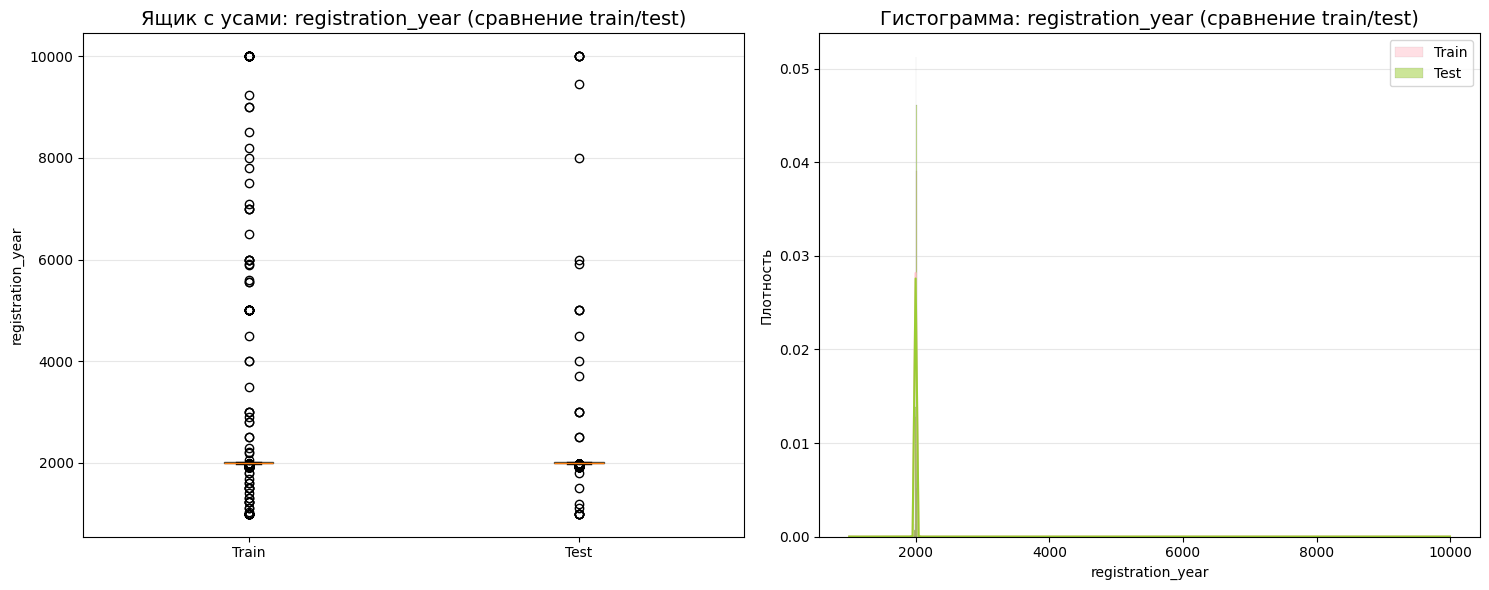


СТАТИСТИКА ДЛЯ 'registration_year':

--- TRAIN ---
Кол-во записей: 265223
Среднее: 2004.063
Стандартное отклонение: 82.188
Медиана: 2003.000
Минимум: 1000.000
Максимум: 9999.000
25-й перцентиль: 1999.000
75-й перцентиль: 2008.000

--- TEST ---
Кол-во записей: 88369
Среднее: 2003.951
Стандартное отклонение: 75.105
Медиана: 2003.000
Минимум: 1000.000
Максимум: 9999.000
25-й перцентиль: 1999.000
75-й перцентиль: 2008.000


In [41]:
plot_quantitative(X_train, X_test, 'registration_year')

TRAIN: удалено 18041 аномальных записей, осталось 247182 строк
TEST: удалено 5944 аномальных записей, осталось 82425 строк


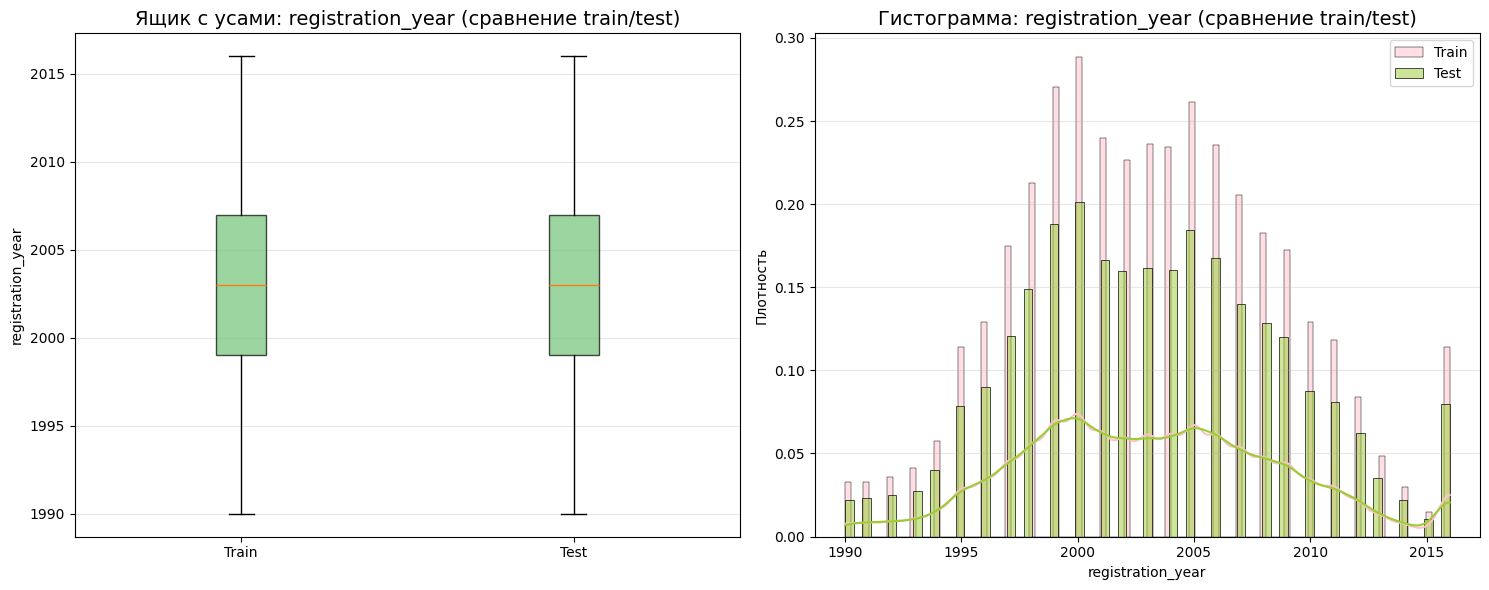


СТАТИСТИКА ДЛЯ 'registration_year':

--- TRAIN ---
Кол-во записей: 247182
Среднее: 2003.151
Стандартное отклонение: 5.636
Медиана: 2003.000
Минимум: 1990.000
Максимум: 2016.000
25-й перцентиль: 1999.000
75-й перцентиль: 2007.000

--- TEST ---
Кол-во записей: 82425
Среднее: 2003.175
Стандартное отклонение: 5.645
Медиана: 2003.000
Минимум: 1990.000
Максимум: 2016.000
25-й перцентиль: 1999.000
75-й перцентиль: 2007.000


In [42]:
# Оставляем записи с 1990 по 2016 год включительно (в обеих выборках)
before_train = len(X_train)
before_test = len(X_test)

X_train = X_train[(X_train['registration_year'] >= 1990) & (X_train['registration_year'] <= 2016)]
X_test = X_test[(X_test['registration_year'] >= 1990) & (X_test['registration_year'] <= 2016)]

# Синхронизируем y_train и y_test с отфильтрованными X
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]

after_train = len(X_train)
after_test = len(X_test)

print(f"TRAIN: удалено {before_train - after_train} аномальных записей, осталось {len(X_train)} строк")
print(f"TEST: удалено {before_test - after_test} аномальных записей, осталось {len(X_test)} строк")

# Визуализация с функцией для двух выборок
plot_quantitative(X_train, X_test, 'registration_year')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">
   
**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `'registration_year'` видим, что есть **аномальные значения** `[TRAIN: удалено 18 041 записей, TEST: удалено 5 944 записи]`.

- `Средний год` регистрации автомобилей в TRAIN — 2003.15, в TEST — 2003.18
- `Медиана:` 2003 — совпадает с серединой распределения в обеих выборках, что указывает на относительно симметричное распределение данных.
- `Минимум:` 1990 — самый ранний год регистрации в выборках.
- `Максимум:` 2016 — самый поздний год регистрации в выборках (верхняя граница, соответствующая году сбора данных).

- `75%` автомобилей зарегистрированы после 1999 года `(25-й перцентиль)`
- `50%` автомобилей зарегистрированы после 2003 года `(медиана)`
- `25%` автомобилей зарегистрированы после 2007 года `(75-й перцентиль)`

МЕЖКВАРТИЛЬНЫЙ РАЗМАХ:

- От 1999 года (25-й перцентиль) до 2007 года (75-й перцентиль).

РАСПРЕДЕЛЕНИЕ:

- Форма близка к нормальной (практически симметричное). Это видно на гистограмме и у ящика с усами — медиана находится в центре, усы практически одинаковы. Медиана (2003) и среднее (2003.15) близки по значению.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

</div>

#### Мощность **`['power']`**

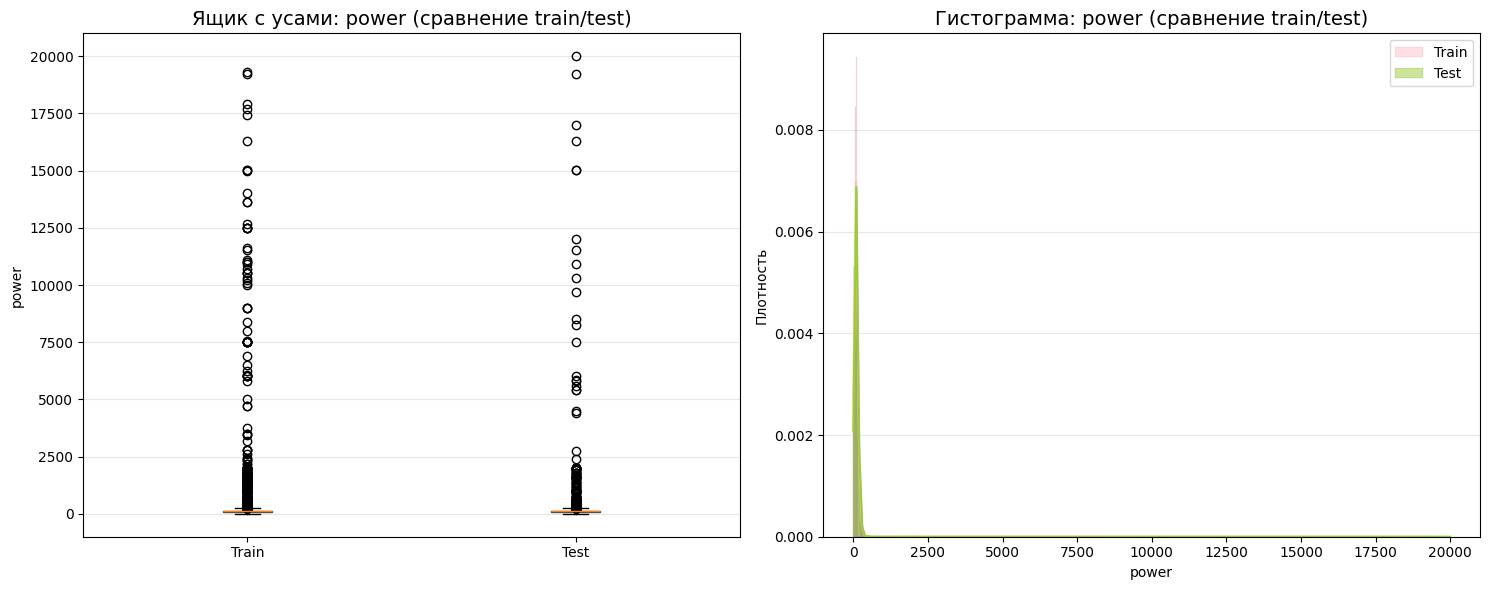


СТАТИСТИКА ДЛЯ 'power':

--- TRAIN ---
Кол-во записей: 247182
Среднее: 111.777
Стандартное отклонение: 180.054
Медиана: 105.000
Минимум: 0.000
Максимум: 19312.000
25-й перцентиль: 71.000
75-й перцентиль: 143.000

--- TEST ---
Кол-во записей: 82425
Среднее: 112.543
Стандартное отклонение: 197.007
Медиана: 105.000
Минимум: 0.000
Максимум: 20000.000
25-й перцентиль: 72.000
75-й перцентиль: 143.000


In [43]:
plot_quantitative(X_train, X_test, 'power')

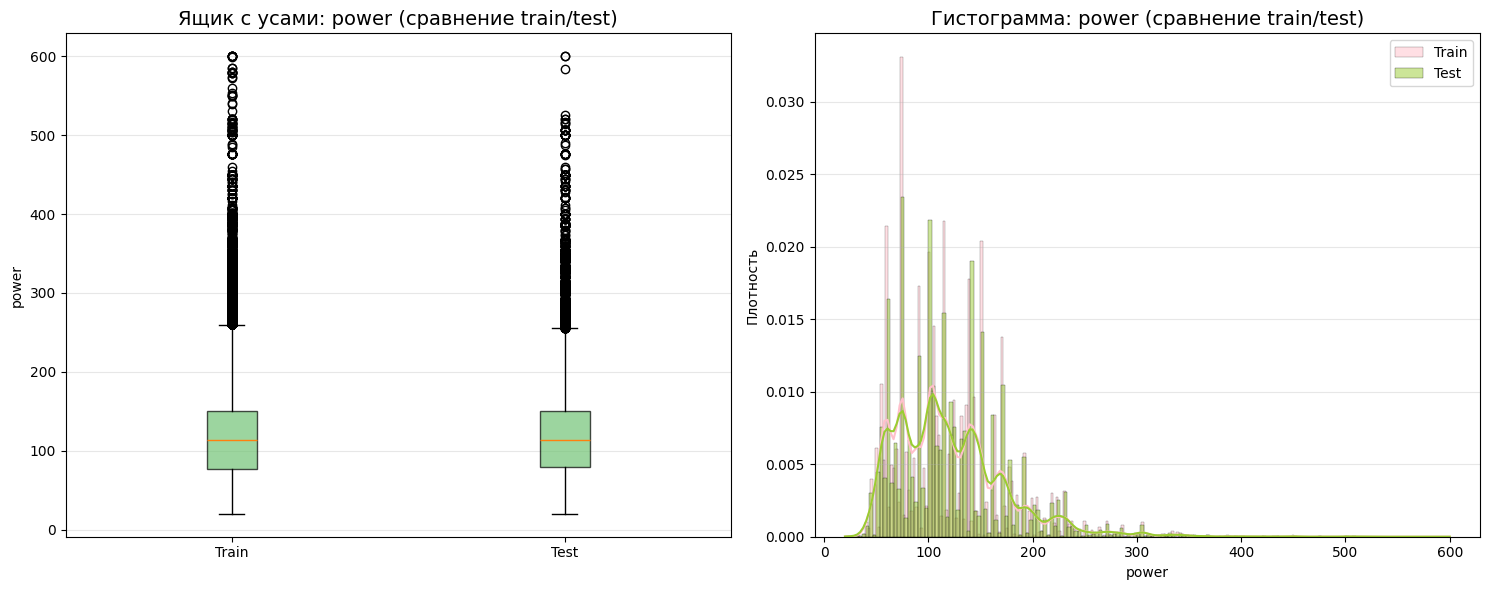


СТАТИСТИКА ДЛЯ 'power':

--- TRAIN ---
Кол-во записей: 221511
Среднее: 120.919
Стандартное отклонение: 53.602
Медиана: 113.000
Минимум: 20.000
Максимум: 600.000
25-й перцентиль: 77.000
75-й перцентиль: 150.000

--- TEST ---
Кол-во записей: 73876
Среднее: 121.287
Стандартное отклонение: 53.681
Медиана: 113.000
Минимум: 20.000
Максимум: 600.000
25-й перцентиль: 80.000
75-й перцентиль: 150.000
TRAIN: удалено 25671 строк с мощностью <20 или >600 л.с., осталось 221511 строк
TEST: удалено 8549 строк с мощностью <20 или >600 л.с., осталось 73876 строк


In [44]:
# Удаление аномалий в обеих выборках
before_train = len(X_train)
before_test = len(X_test)

# Фильтрация по мощности (20-600 л.с.)
X_train = X_train[(X_train['power'] >= 20) & (X_train['power'] <= 600)]
X_test = X_test[(X_test['power'] >= 20) & (X_test['power'] <= 600)]

# Синхронизируем y_train и y_test
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]

after_train = len(X_train)
after_test = len(X_test)

# Визуализация с функцией для двух выборок
plot_quantitative(X_train, X_test, 'power')

print(f"TRAIN: удалено {before_train - after_train} строк с мощностью <20 или >600 л.с., осталось {len(X_train)} строк")
print(f"TEST: удалено {before_test - after_test} строк с мощностью <20 или >600 л.с., осталось {len(X_test)} строк")

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">
   
**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `power` видим, что есть **аномальные значения**: мощность 0 л.с. и более 600 л.с. `[TRAIN: удалено 25 671 запись, TEST: удалено 8 549 записей]`.

- `Средняя` мощность автомобиля в TRAIN — 120.9 л.с., в TEST — 121.3 л.с.
- `Медиана:` 113 л.с. — находится левее среднего значения в обеих выборках, что указывает на правостороннюю асимметрию (есть автомобили с высокой мощностью, "вытягивающие" среднее вверх).
- `Минимум:` 20 л.с. — минимальная мощность в выборках после очистки.
- `Максимум:` 600 л.с. — максимальная мощность в выборках.
- `75%` автомобилей имеют мощность более 77-80 л.с. `(25-й перцентиль)`
- `50%` автомобилей имеют мощность более 113 л.с. `(медиана)`
- `25%` автомобилей имеют мощность более 150 л.с. `(75-й перцентиль)`

МЕЖКВАРТИЛЬНЫЙ РАЗМАХ

- От 77-80 л.с. (25-й перцентиль) до 150 л.с. (75-й перцентиль).
- Наибольшее количество автомобилей (пик гистограммы) приходится на диапазон 77–113 л.с.

РАСПРЕДЕЛЕНИЕ

- Форма распределения **имеет правостороннюю асимметрию** (скошено вправо).
- Это видно на гистограмме: длинный "хвост" уходит в сторону больших значений мощности до 600 л.с., а также по ящику с усами — медиана смещена левее центра ящика, усы неравномерны.
- Среднее (120.9-121.3) больше медианы (113), что также подтверждает наличие выбросов в правой части распределения.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

</div>

#### Цена в евро **`['price']`**

In [45]:
def plot_quantitative_series(y_train, y_test, column='price', figsize=(15, 6), palette='Greens'):
    '''Ящик с усами и Гистограмма для целевого признака (Series)'''
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    color = sns.color_palette(palette, 1)[0]
    
    # 1. Ящик с усами
    data_to_plot = [y_train.dropna(), y_test.dropna()]
    bp = ax1.boxplot(data_to_plot, labels=['Train', 'Test'], patch_artist=True)
    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax1.set_title(f'Ящик с усами: {column} (сравнение train/test)', fontsize=14)
    ax1.set_ylabel(column)
    ax1.grid(axis='y', alpha=0.3)
    
    # 2. Гистограммы
    sns.histplot(y_train, kde=True, color='pink', alpha=0.5, label='Train', ax=ax2, stat='density')
    sns.histplot(y_test, kde=True, color='yellowgreen', alpha=0.5, label='Test', ax=ax2, stat='density')
    
    ax2.set_title(f'Гистограмма: {column} (сравнение train/test)', fontsize=14)
    ax2.set_xlabel(column)
    ax2.set_ylabel('Плотность')
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Статистика
    print(f"\n{'='*50}")
    print(f"СТАТИСТИКА ДЛЯ '{column}':")
    print(f"{'='*50}")
    
    print("\n--- TRAIN ---")
    print(f"Кол-во записей: {len(y_train):.0f}")
    print(f"Среднее: {y_train.mean():.3f}")
    print(f"Стандартное отклонение: {y_train.std():.3f}")
    print(f"Медиана: {y_train.median():.3f}")
    print(f"Минимум: {y_train.min():.3f}")
    print(f"Максимум: {y_train.max():.3f}")
    print(f"25-й перцентиль: {y_train.quantile(0.25):.3f}")
    print(f"75-й перцентиль: {y_train.quantile(0.75):.3f}")
    
    print("\n--- TEST ---")
    print(f"Кол-во записей: {len(y_test):.0f}")
    print(f"Среднее: {y_test.mean():.3f}")
    print(f"Стандартное отклонение: {y_test.std():.3f}")
    print(f"Медиана: {y_test.median():.3f}")
    print(f"Минимум: {y_test.min():.3f}")
    print(f"Максимум: {y_test.max():.3f}")
    print(f"25-й перцентиль: {y_test.quantile(0.25):.3f}")
    print(f"75-й перцентиль: {y_test.quantile(0.75):.3f}")

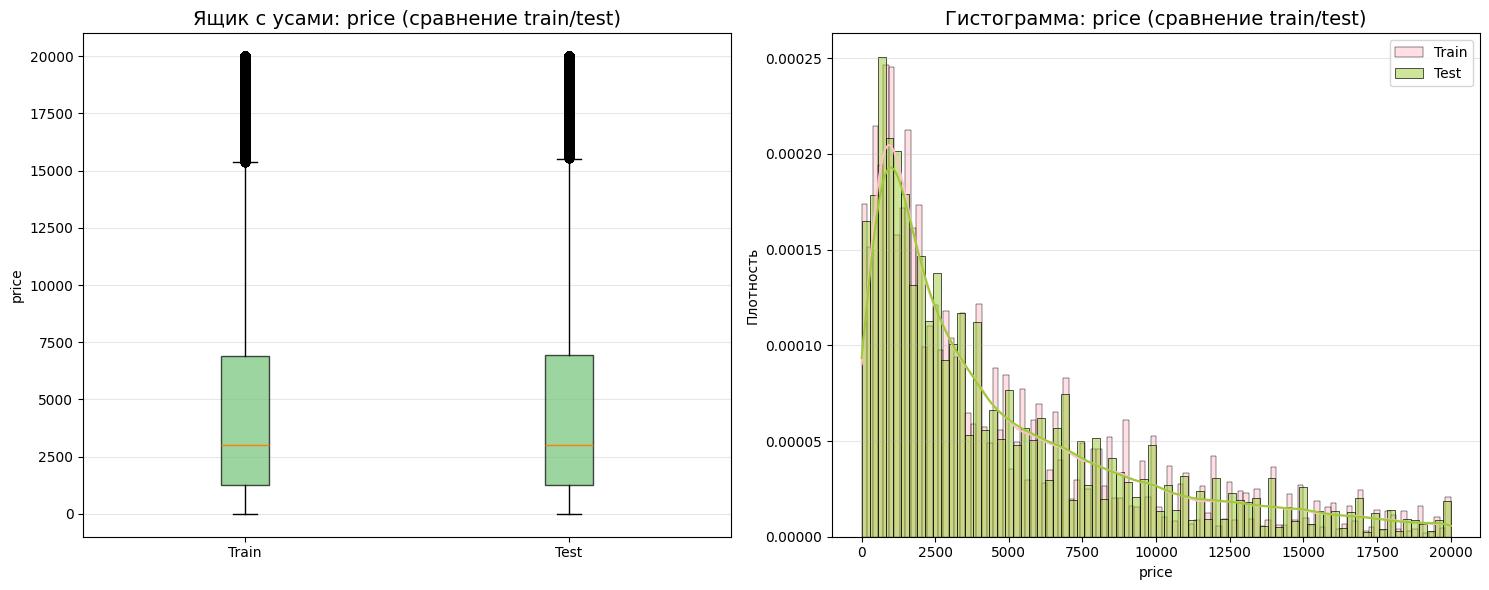


СТАТИСТИКА ДЛЯ 'price':

--- TRAIN ---
Кол-во записей: 221511
Среднее: 4735.297
Стандартное отклонение: 4605.777
Медиана: 3000.000
Минимум: 0.000
Максимум: 20000.000
25-й перцентиль: 1250.000
75-й перцентиль: 6900.000

--- TEST ---
Кол-во записей: 73876
Среднее: 4762.590
Стандартное отклонение: 4623.132
Медиана: 3000.000
Минимум: 0.000
Максимум: 20000.000
25-й перцентиль: 1250.000
75-й перцентиль: 6950.000


In [46]:
# Использование
plot_quantitative_series(y_train, y_test, 'price')

In [47]:
# 1. Удаление строк с нулевой ценой
zero_price_idx_train = y_train[y_train == 0].index
zero_price_idx_test = y_test[y_test == 0].index

X_train = X_train.drop(index=zero_price_idx_train)
y_train = y_train.drop(index=zero_price_idx_train)

X_test = X_test.drop(index=zero_price_idx_test)
y_test = y_test.drop(index=zero_price_idx_test)

print(f"TRAIN: удалено {len(zero_price_idx_train)} строк с ценой 0")
print(f"TEST: удалено {len(zero_price_idx_test)} строк с ценой 0")



# 2. Удаление бюджетных брендов с ценой 20000
budget_brands = ['volkswagen', 'opel', 'seat', 'ford', 'kia', 'skoda', 
                 'renault', 'peugeot', 'fiat', 'hyundai', 'citroen', 
                 'dacia', 'chevrolet', 'mazda']

# Для TRAIN
mask_train = (y_train == 20000) & (X_train['brand'].isin(budget_brands))
idx_to_drop_train = mask_train[mask_train].index

# Для TEST
mask_test = (y_test == 20000) & (X_test['brand'].isin(budget_brands))
idx_to_drop_test = mask_test[mask_test].index

X_train = X_train.drop(index=idx_to_drop_train)
y_train = y_train.drop(index=idx_to_drop_train)

X_test = X_test.drop(index=idx_to_drop_test)
y_test = y_test.drop(index=idx_to_drop_test)



print(f"TRAIN: удалено {len(idx_to_drop_train)} бюджетных брендов с ценой 20000")
print(f"TEST: удалено {len(idx_to_drop_test)} бюджетных брендов с ценой 20000")

print(f"\nФИНАЛЬНЫЕ РАЗМЕРЫ:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

TRAIN: удалено 4527 строк с ценой 0
TEST: удалено 1544 строк с ценой 0
TRAIN: удалено 43 бюджетных брендов с ценой 20000
TEST: удалено 15 бюджетных брендов с ценой 20000

ФИНАЛЬНЫЕ РАЗМЕРЫ:
X_train: (216941, 10), y_train: (216941,)
X_test: (72317, 10), y_test: (72317,)


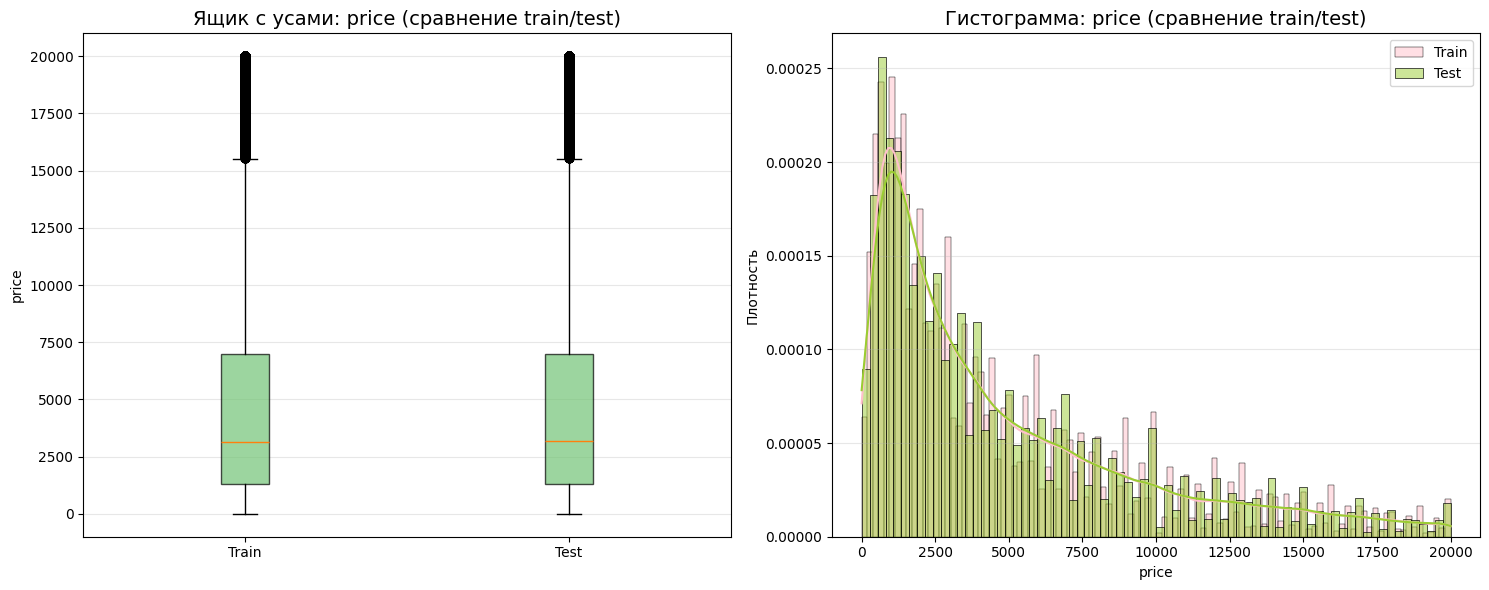


СТАТИСТИКА ДЛЯ 'price':

--- TRAIN ---
Кол-во записей: 216941
Среднее: 4831.085
Стандартное отклонение: 4597.475
Медиана: 3150.000
Минимум: 1.000
Максимум: 20000.000
25-й перцентиль: 1300.000
75-й перцентиль: 6990.000

--- TEST ---
Кол-во записей: 72317
Среднее: 4861.112
Стандартное отклонение: 4614.323
Медиана: 3200.000
Минимум: 1.000
Максимум: 20000.000
25-й перцентиль: 1300.000
75-й перцентиль: 6999.000


In [48]:
# Создаем временные DataFrame для визуализации
X_train_price = pd.DataFrame({'price': y_train})
X_test_price = pd.DataFrame({'price': y_test})

plot_quantitative(X_train_price, X_test_price, 'price')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `price` видим, что есть **аномальные значения**: цена 0 евро и завышенная цена 20 000 евро для бюджетных брендов 

`[TRAIN: удалено 4 527 строк с ценой 0 евро, 43 аномальных записи для бюджетных брендов; TEST: удалено 1 544 строки с ценой 0 евро, 15 аномальных записей для бюджетных брендов]`.

- `Средняя` цена автомобиля в TRAIN — 4 831 евро, в TEST — 4 861 евро.
- `Медиана:` 3 150 евро (TRAIN) и 3 200 евро (TEST) — находится левее среднего значения, что указывает на правостороннюю асимметрию (есть автомобили с высокой ценой, "вытягивающие" среднее вверх).
- `Минимум:` 1 евро — минимальная цена в выборках после очистки (символическая цена).
- `Максимум:` 20 000 евро — максимальная цена в выборках (верхняя граница датасета).
- `75%` автомобилей имеют цену более 1 300 евро `(25-й перцентиль)`
- `50%` автомобилей имеют цену более 3 150-3 200 евро `(медиана)`
- `25%` автомобилей имеют цену более 6 990-6 999 евро `(75-й перцентиль)`

МЕЖКВАРТИЛЬНЫЙ РАЗМАХ

- От 1 300 евро (25-й перцентиль) до 6 990-6 999 евро (75-й перцентиль).
- Наибольшее количество автомобилей (пик гистограммы) приходится на диапазон 1 000–3 000 евро.

РАСПРЕДЕЛЕНИЕ

- Форма распределения **имеет правостороннюю асимметрию** (скошено вправо).
- Это видно на гистограмме: длинный "хвост" уходит в сторону больших значений цены до 20 000 евро, а также по ящику с усами — медиана смещена левее центра ящика, правый ус значительно длиннее левого.
- Среднее (4 831-4 861) больше медианы (3 150-3 200), что также подтверждает наличие выбросов в правой части распределения (дорогие автомобили).
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

</div>

#### Индекс владельца **`['postal_code']`**

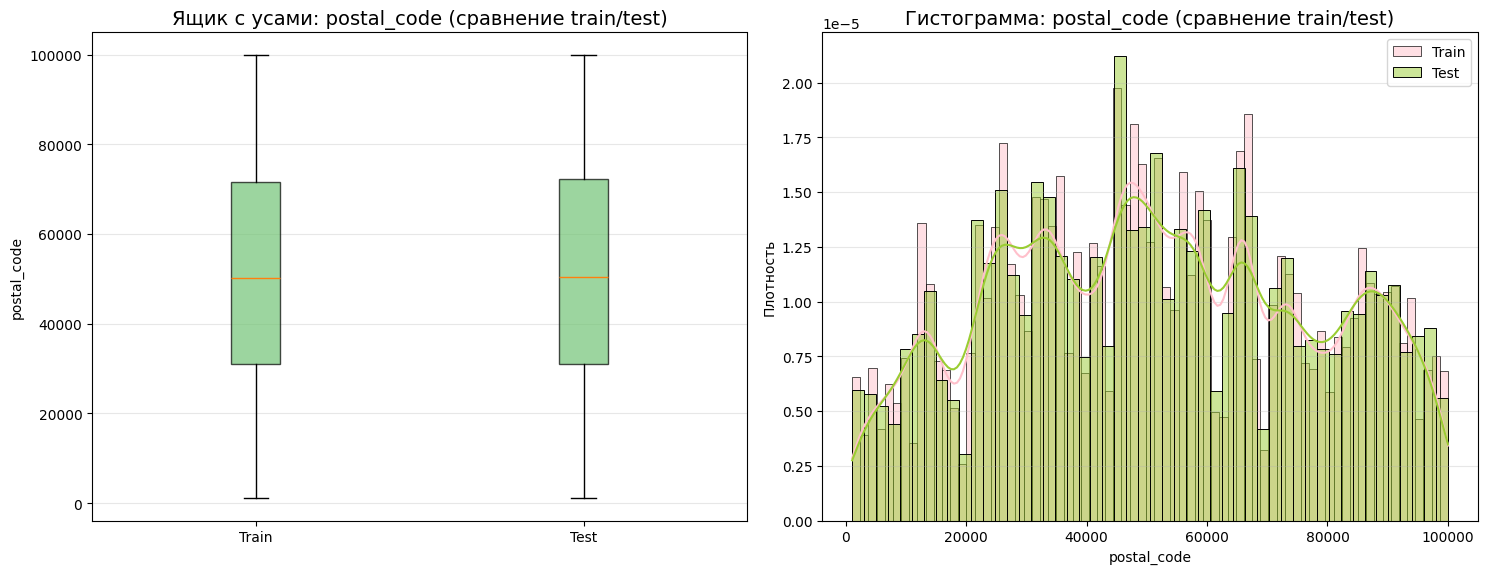


СТАТИСТИКА ДЛЯ 'postal_code':

--- TRAIN ---
Кол-во записей: 216941
Среднее: 51198.315
Стандартное отклонение: 25733.980
Медиана: 50189.000
Минимум: 1067.000
Максимум: 99998.000
25-й перцентиль: 30952.000
75-й перцентиль: 71706.000

--- TEST ---
Кол-во записей: 72317
Среднее: 51334.065
Стандартное отклонение: 25798.630
Медиана: 50374.000
Минимум: 1067.000
Максимум: 99998.000
25-й перцентиль: 30952.000
75-й перцентиль: 72202.000


In [49]:
plot_quantitative(X_train, X_test, 'postal_code')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `postal_code` видим, что данные представлены **широким диапазоном почтовых индексов** (от 1067 до 99998), характерным для Германии.

- `Среднее` значение почтового индекса в TRAIN — 51 077, в TEST — 51 223.
- `Медиана:` 50 126 (TRAIN) и 50 259 (TEST) — находится близко к среднему значению, что указывает на **относительно симметричное распределение**.
- `Минимум:` 1 067 — наименьший почтовый индекс в выборках (регион на востоке Германии).
- `Максимум:` 99 998 — наибольший почтовый индекс в выборках.
- `75%` владельцев имеют почтовый индекс более 30 890 `(25-й перцентиль)`
- `50%` владельцев имеют почтовый индекс более 50 126-50 259 `(медиана)`
- `25%` владельцев имеют почтовый индекс более 71 665-72 135 `(75-й перцентиль)`

МЕЖКВАРТИЛЬНЫЙ РАЗМАХ

- От 30 890 (25-й перцентиль) до 71 665-72 135 (75-й перцентиль).
- Разброс охватывает практически всю территорию Германии.

РАСПРЕДЕЛЕНИЕ

- Распределение **близко к нормальному** с небольшими пиками в крупных городах.
- Почтовые индексы охватывают всю территорию Германии от восточных (1xxx) до западных (9xxxx) регионов.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

---

- Признак `postal_code` **косвенно указывает на регион** продажи автомобиля.
- Влияет на цену (разный уровень дохода в разных регионах, разная транспортная доступность).

</div>

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Исследование категориальных признаков

<span style="color:yellowgreen">
    
- <span style="color:black">Рассмотрим ближе признаки и распределение значений в них.

к а т е г о р и а л ь н ы е

- `brand`
- `model` <span style="color:black">[Поправили неявные дубликаты (снизили кол-во на 6 уникальных значений)]
- `vehicle_type` <span style="color:black"> [Объединили gasoline c petrol]
- `gearbox`
- `fuel_type`
- `kilometer`
- `repaired`

In [50]:
def plot_categorical_compare(df_train, df_test, col, figsize=(15, 14), palette='PiYG', top_n=15, max_cat=50):
    """
    Сравнивает распределение категориального признака в train и test выборках
    (столбчатая диаграмма со stacked bars, круговая диаграмма для train)
    """
    vc_train = df_train[col].value_counts()
    vc_test = df_test[col].value_counts()
    total_train = len(df_train)
    total_test = len(df_test)
    dom_pct_train = vc_train.iloc[0] / total_train * 100
    
    # Вспомогательная функция для вывода статистики и таблицы
    def print_stats(table_max=None):
        print(f"\n{'='*70}\nСтатистика для '{col}':\n{'='*70}")
        
        print("\n--- TRAIN ---")
        print(f"Всего записей: {total_train:,}")
        print(f"Уникальных категорий: {df_train[col].nunique():,}")
        print(f"Самая частая: '{vc_train.index[0]}' ({vc_train.iloc[0]:,}, {vc_train.iloc[0]/total_train*100:.1f}%)")
        print(f"Самая редкая: '{vc_train.index[-1]}' ({vc_train.iloc[-1]:,}, {vc_train.iloc[-1]/total_train*100:.1f}%)")
        rare_train = vc_train[vc_train/total_train < 0.01]
        if len(rare_train):
            print(f"Кол-во редких категорий (<1%): {len(rare_train)}, {rare_train.sum()/total_train*100:.1f}%")
        
        print("\n--- TEST ---")
        print(f"Всего записей: {total_test:,}")
        print(f"Уникальных категорий: {df_test[col].nunique():,}")
        print(f"Самая частая: '{vc_test.index[0]}' ({vc_test.iloc[0]:,}, {vc_test.iloc[0]/total_test*100:.1f}%)")
        print(f"Самая редкая: '{vc_test.index[-1]}' ({vc_test.iloc[-1]:,}, {vc_test.iloc[-1]/total_test*100:.1f}%)")
        rare_test = vc_test[vc_test/total_test < 0.01]
        if len(rare_test):
            print(f"Кол-во редких категорий (<1%): {len(rare_test)}, {rare_test.sum()/total_test*100:.1f}%")
        
        # Сводная таблица (топ-20)
        compare_df = pd.DataFrame({'Train': vc_train, 'Test': vc_test}).fillna(0).astype(int)
        compare_df = compare_df.sort_values('Train', ascending=False)
        
        print(f"\n{'='*70}\nСВОДНАЯ ТАБЛИЦА (топ-20 из {len(compare_df)}) для '{col}':\n{'='*70}")
        
        rows = []
        for i, (cat, row) in enumerate(compare_df.head(20).iterrows(), 1):
            cnt_train = row['Train']
            cnt_test = row['Test']
            pct_train = cnt_train / total_train * 100
            pct_test = cnt_test / total_test * 100
            rows.append([i, cat, f"{cnt_train:,}", f"{pct_train:.2f}%", f"{cnt_test:,}", f"{pct_test:.2f}%"])
        
        print(pd.DataFrame(rows, columns=['№', 'Категория', 'Train_Кол-во', 'Train_%', 'Test_Кол-во', 'Test_%']).to_string(index=False))
        if len(compare_df) > 20:
            print(f"\n... и еще {len(compare_df) - 20} категорий")
    
    # Случай 1: слишком много категорий
    if len(vc_train) > max_cat or len(vc_test) > max_cat:
        print_stats(table_max=20)
        return None
    
    # Случай 2: доминирующая категория (>90%) - только столбчатая
    if dom_pct_train > 90:
        fig, ax = plt.subplots(figsize=(figsize[0], figsize[1]//2))
        
        # Проверяем количество категорий для выбора ориентации
        n_categories = len(set(vc_train.index) | set(vc_test.index))
        is_horizontal = n_categories > 7  # ← если >7 категорий - горизонтальная, иначе вертикальная
        
        # Объединяем категории из train и test
        all_cats = sorted(set(vc_train.index) | set(vc_test.index))
        train_vals = [vc_train.get(cat, 0) for cat in all_cats]
        test_vals = [vc_test.get(cat, 0) for cat in all_cats]
        
        if is_horizontal:
            y_pos = range(len(all_cats))
            height = 0.5
            bars1 = ax.barh([y - height/2 for y in y_pos], train_vals, height, label='Train', color='yellowgreen', alpha=0.8)
            bars2 = ax.barh([y + height/2 for y in y_pos], test_vals, height, label='Test', color='#f4acb7', alpha=0.8)
            ax.set_yticks(y_pos)
            ax.set_yticklabels(all_cats, fontsize=9)
            ax.set_xlabel('Количество')
            ax.set_ylabel(col)
            ax.legend()
            ax.invert_yaxis()
            
            for i, (train_val, test_val) in enumerate(zip(train_vals, test_vals)):
                if train_val > 0:
                    ax.text(train_val, i - height/2, f'{train_val:,}', va='center', ha='left', fontsize=7)
                if test_val > 0:
                    ax.text(test_val, i + height/2, f'{test_val:,}', va='center', ha='left', fontsize=7)
        else:
            # Вертикальная диаграмма для <=7 категорий
            x_pos = range(len(all_cats))
            width = 0.35
            bars1 = ax.bar([x - width/2 for x in x_pos], train_vals, width, label='Train', color='yellowgreen', alpha=0.8)
            bars2 = ax.bar([x + width/2 for x in x_pos], test_vals, width, label='Test', color='#f4acb7', alpha=0.8)
            ax.set_xticks(x_pos)
            ax.set_xticklabels(all_cats, rotation=45, ha='right', fontsize=9)
            ax.set_xlabel(col)
            ax.set_ylabel('Количество')
            ax.legend()
            ax.grid(axis='y', alpha=0.3)
            
            for bar in bars1:
                height = bar.get_height()
                if height > 0:
                    ax.text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', ha='center', va='bottom', fontsize=7)
            for bar in bars2:
                height = bar.get_height()
                if height > 0:
                    ax.text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', ha='center', va='bottom', fontsize=7)
        
        ax.set_title(f'{col} (доминирует: {vc_train.index[0]} - {dom_pct_train:.1f}%)', fontweight='bold')
        ax.grid(axis='x' if is_horizontal else 'y', alpha=0.3)
        plt.tight_layout()
        print_stats()
        plt.show()
        return None
    
    # Случай 3: обычный - два графика
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize)
    
    # Проверяем количество категорий для выбора ориентации
    n_categories = len(set(vc_train.index) | set(vc_test.index))
    is_horizontal = n_categories > 7  # ← если >7 категорий - горизонтальная, иначе вертикальная
    
    top_cats = pd.DataFrame({'Train': vc_train, 'Test': vc_test}).fillna(0).astype(int)
    top_cats = top_cats.sort_values('Train', ascending=False).head(top_n).index
    train_top = vc_train[top_cats]
    test_top = vc_test[top_cats]
    
    if is_horizontal:
        # Горизонтальная диаграмма (stacked bars)
        y_pos = range(len(top_cats))
        height = 0.5
        
        bars1 = ax1.barh(y_pos, train_top, height, label='Train', color='yellowgreen', alpha=0.8)
        bars2 = ax1.barh(y_pos, test_top, height, left=train_top, label='Test', color='#f4acb7', alpha=0.8)
        
        ax1.set_yticks(y_pos)
        ax1.set_yticklabels(top_cats, fontsize=9)
        ax1.set_xlabel('Количество')
        ax1.set_title(f'{col} (топ-{top_n}, сравнение train/test)')
        ax1.legend()
        ax1.invert_yaxis()
        ax1.grid(axis='x', alpha=0.3)
        
        # Добавляем общую сумму справа
        for i, (train_val, test_val) in enumerate(zip(train_top, test_top)):
            total_val = train_val + test_val
            if total_val > 0:
                ax1.text(total_val + 100, i, f'{total_val:,}', va='center', ha='left', fontsize=7, color='gray')
    else:
        # Вертикальная диаграмма для <=7 категорий
        x_pos = range(len(top_cats))
        width = 0.35
        
        bars1 = ax1.bar([x - width/2 for x in x_pos], train_top, width, label='Train', color='yellowgreen', alpha=0.8)
        bars2 = ax1.bar([x + width/2 for x in x_pos], test_top, width, label='Test', color='#f4acb7', alpha=0.8)
        
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(top_cats, rotation=45, ha='right', fontsize=9)
        ax1.set_xlabel(col)
        ax1.set_ylabel('Количество')
        ax1.set_title(f'{col} (топ-{top_n}, сравнение train/test)')
        ax1.legend()
        ax1.grid(axis='y', alpha=0.3)
        
        # Добавляем значения на столбцы
        for bar in bars1:
            height = bar.get_height()
            if height > 0:
                ax1.text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', ha='center', va='bottom', fontsize=7)
        for bar in bars2:
            height = bar.get_height()
            if height > 0:
                ax1.text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', ha='center', va='bottom', fontsize=7)
    
    # График 2: Круговая диаграмма для train
    if len(vc_train) > top_n:
        pie_data = pd.concat([vc_train.head(top_n), pd.Series({'Другие': vc_train.iloc[top_n:].sum()})])
        pie_title = f'{col} (Train, топ-{top_n}, +{len(vc_train)-top_n} др.)'
    else:
        pie_data = vc_train
        pie_title = f'{col} (Train, все {len(vc_train)} категорий)'
    
    text_size = 8 if len(pie_data) > 15 else (9 if len(pie_data) > 10 else 10)
    colors = sns.color_palette(palette, len(pie_data))
    
    def autopct(p):
        return f'{p:.1f}%' if p > 2 else ''
    
    wedges, texts, autotexts = ax2.pie(pie_data, labels=pie_data.index, autopct=autopct,
                                        colors=colors, startangle=90, textprops={'fontsize': text_size},
                                        pctdistance=0.85, labeldistance=1.08)
    for at in autotexts:
        if at.get_text():
            at.set_color('white')
            at.set_fontweight('bold')
    
    ax2.set_title(pie_title, fontweight='bold')
    plt.tight_layout()
    
    print_stats()
    plt.show()
    return None

#### Бренд **`['brand']`**


Статистика для 'brand':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 40
Самая частая: 'volkswagen' (46,800, 21.6%)
Самая редкая: 'trabant' (25, 0.0%)
Кол-во редких категорий (<1%): 22, 7.9%

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 40
Самая частая: 'volkswagen' (15,528, 21.5%)
Самая редкая: 'trabant' (12, 0.0%)
Кол-во редких категорий (<1%): 23, 8.8%

СВОДНАЯ ТАБЛИЦА (топ-20 из 40) для 'brand':
 №     Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1    volkswagen       46,800  21.57%      15,528 21.47%
 2          opel       23,969  11.05%       8,092 11.19%
 3           bmw       23,699  10.92%       8,016 11.08%
 4 mercedes_benz       19,483   8.98%       6,580  9.10%
 5          audi       18,909   8.72%       6,334  8.76%
 6          ford       15,368   7.08%       4,999  6.91%
 7       renault       10,339   4.77%       3,486  4.82%
 8       peugeot        7,083   3.26%       2,304  3.19%
 9          fiat        5,619   2.59%       1,839  2.54%


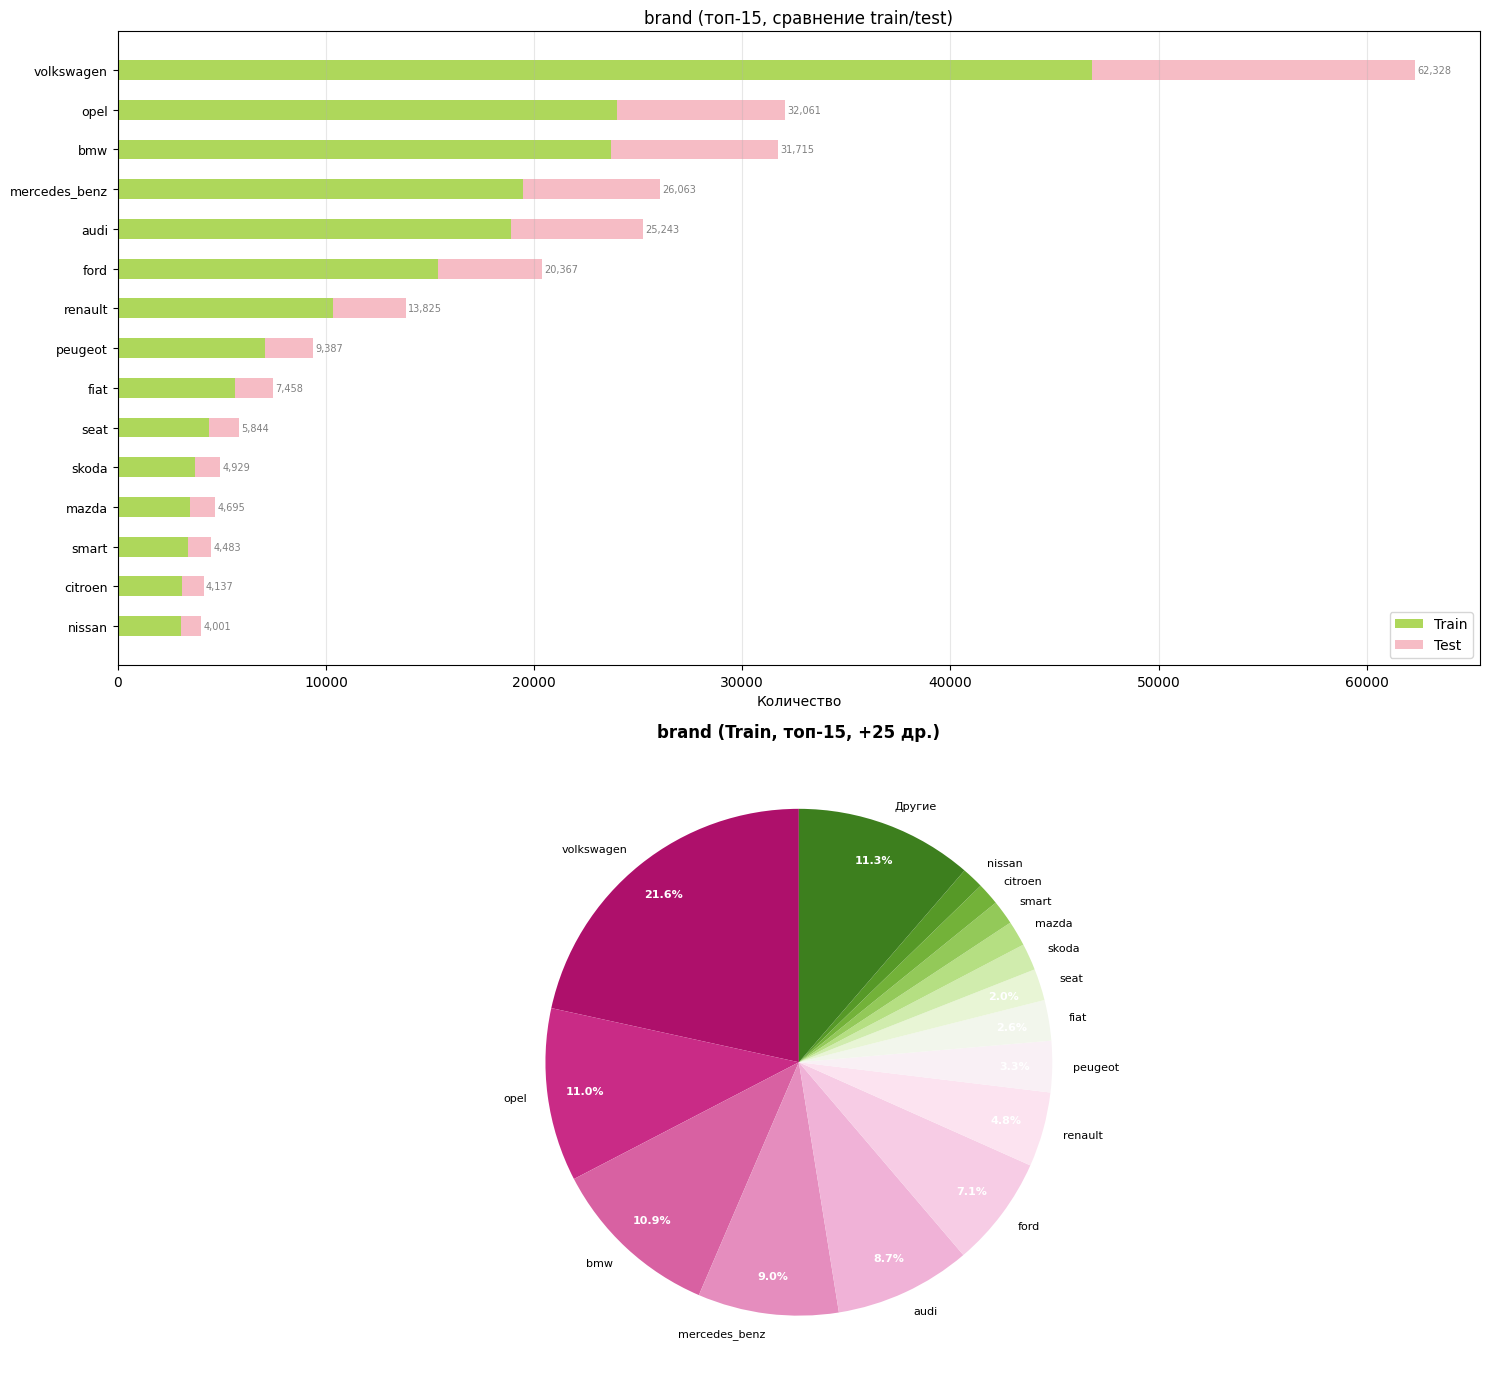

In [51]:
plot_categorical_compare(X_train, X_test, 'brand')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `brand` видим, что данные представлены **40 уникальными марками** с сильным **перекосом в сторону массовых брендов**.

- `Наиболее частая марка:` Volkswagen — 46 800 автомобилей в TRAIN **(21.6%)** и 15 528 в TEST **(21.5%)**
- `Топ-3 марок` (Volkswagen, Opel, BMW) занимают **43.5%** (TRAIN) и **43.7%** (TEST) всех автомобилей в выборках
- `Топ-5 марок` (до Audi включительно) занимают **61.3%** (TRAIN) и **61.6%** (TEST) данных
- `Редкие марки` (<1% от выборки): **22 марки** в TRAIN (55% от всех марок), совокупно занимают **7.9%** данных; **23 марки** в TEST (57.5%), совокупно занимают **8.8%** данных
- `Наиболее редкая марка:` Trabant — 25 автомобилей в TRAIN **(0.01%)** и 12 в TEST **(0.02%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **ярко выраженную правостороннюю асимметрию** (длинный "хвост" редких марок).
- **Дисбаланс:** 5 массовых марок занимают более 60% данных, тогда как редкие марки — менее 9%.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

КОНЦЕНТРАЦИЯ ДАННЫХ

| Категория | Количество марок | Доля марок | Доля записей (Train/Test) |
|:---|:---|:---|:---|
| Топ-5 марок | 5 | 12.5% | 61.3% / 61.6% |
| Топ-10 марок | 10 | 25% | 81.1% / 81.1% |
| Редкие (<1%) | 22-23 | 55-57.5% | 7.9% / 8.8% |

КОММЕНТАРИЙ

Модели градиентного бустинга (LightGBM, CatBoost) хорошо работают с категориальными признаками с большим количеством категорий

</div>

#### Тип кузова **`['vehicle_type']`**


Статистика для 'vehicle_type':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 8
Самая частая: 'sedan' (62,499, 28.8%)
Самая редкая: 'other' (1,851, 0.9%)
Кол-во редких категорий (<1%): 1, 0.9%

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 8
Самая частая: 'sedan' (20,772, 28.7%)
Самая редкая: 'other' (652, 0.9%)
Кол-во редких категорий (<1%): 1, 0.9%

СВОДНАЯ ТАБЛИЦА (топ-20 из 8) для 'vehicle_type':
 №   Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1       sedan       62,499  28.81%      20,772 28.72%
 2       small       53,197  24.52%      17,378 24.03%
 3       wagon       44,481  20.50%      14,982 20.72%
 4         bus       20,994   9.68%       6,961  9.63%
 5 convertible       14,699   6.78%       4,958  6.86%
 6       coupe       11,212   5.17%       3,882  5.37%
 7         suv        8,008   3.69%       2,732  3.78%
 8       other        1,851   0.85%         652  0.90%


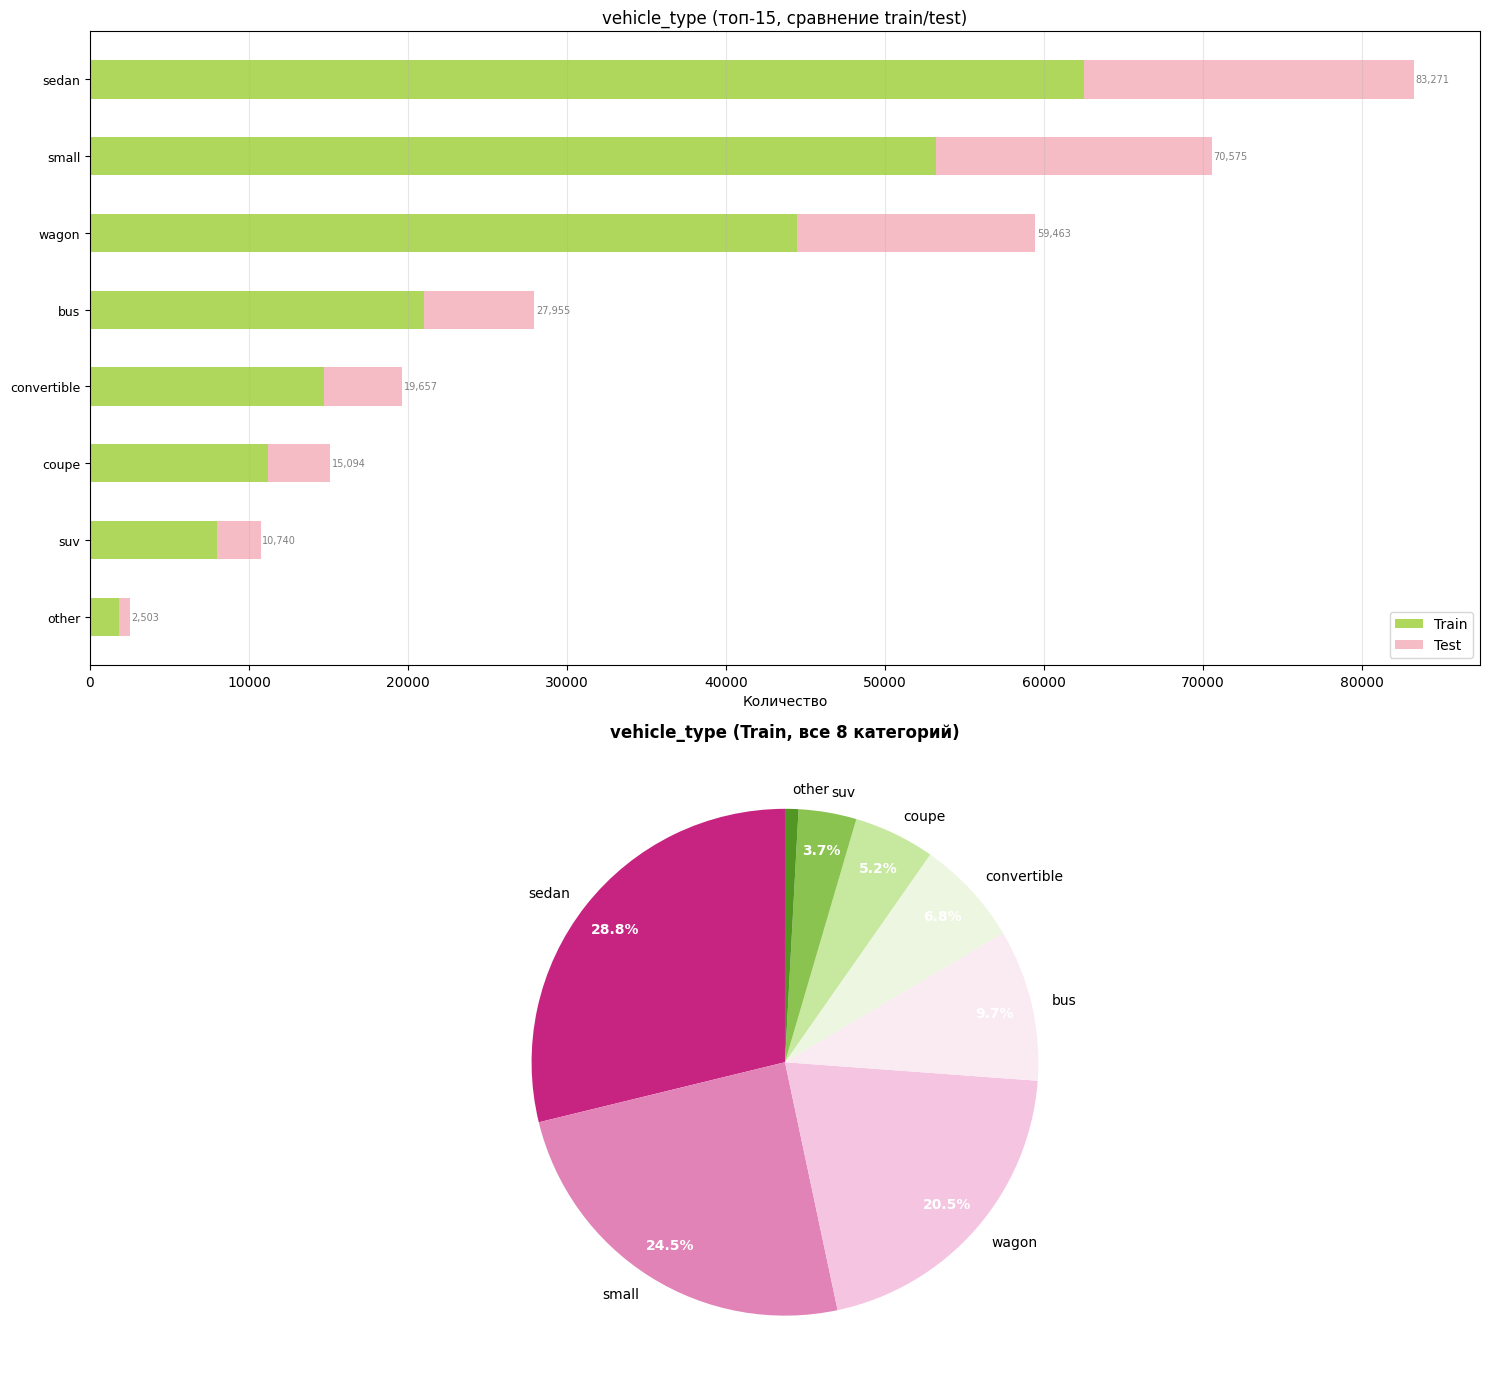

In [52]:
plot_categorical_compare(X_train, X_test, 'vehicle_type')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `vehicle_type` видим, что данные представлены **8 типами кузова** с **неравномерным распределением**.

- `Наиболее частый тип кузова:` sedan — 62 499 автомобилей в TRAIN **(28.8%)** и 20 772 в TEST **(28.7%)**
- `Топ-3 типа кузова` (sedan, small, wagon) занимают **73.8%** (TRAIN) и **73.5%** (TEST) всех автомобилей в выборках
- `Топ-5 типов кузова` (до convertible включительно) занимают **90.3%** (TRAIN) и **90.0%** (TEST) данных
- `Редкие типы кузова` (<1% от выборки): **other** — 1 851 автомобиль в TRAIN **(0.85%)** и 652 в TEST **(0.90%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **умеренную правостороннюю асимметрию** (длинный "хвост" редких типов кузова).
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

| Категория | Количество типов | Доля типов | Доля записей (Train/Test) |
|:---|:---|:---|:---|
| Топ-3 типа | 3 | 37.5% | 73.8% / 73.5% |
| Топ-5 типов | 5 | 62.5% | 90.3% / 90.0% |
| Редкие (<1%) | 1 | 12.5% | 0.85% / 0.90% |

</div>

#### Модель **`['model']`**

In [53]:
plot_categorical_compare(X_train, X_test, 'model')


Статистика для 'model':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 243
Самая частая: 'golf' (18,549, 8.6%)
Самая редкая: 'range_rover_evoque' (1, 0.0%)
Кол-во редких категорий (<1%): 218, 33.6%

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 242
Самая частая: 'golf' (6,194, 8.6%)
Самая редкая: 'range_rover_evoque' (1, 0.0%)
Кол-во редких категорий (<1%): 217, 33.7%

СВОДНАЯ ТАБЛИЦА (топ-20 из 243) для 'model':
 №   Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1        golf       18,549   8.55%       6,194  8.57%
 2    3_series       15,585   7.18%       5,322  7.36%
 3 other_model       14,642   6.75%       4,843  6.70%
 4        polo        7,997   3.69%       2,655  3.67%
 5       corsa        7,700   3.55%       2,572  3.56%
 6       astra        7,130   3.29%       2,436  3.37%
 7          a4        6,733   3.10%       2,205  3.05%
 8      passat        6,538   3.01%       2,235  3.09%
 9     c_class        5,696   2.63%       1,883  2.60%
10    5_

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `model` видим, что данные представлены **243 уникальными моделями** в TRAIN и **242** в TEST с **сильным перекосом** в сторону популярных моделей.

- `Наиболее частая модель:` Golf — 18 549 автомобилей в TRAIN **(8.6%)** и 6 194 в TEST **(8.6%)**
- `Топ-3 моделей` (Golf, 3_series, other_model) занимают **22.5%** (TRAIN) и **22.6%** (TEST) всех автомобилей в выборках
- `Топ-10 моделей` занимают **44.2%** (TRAIN) и **44.6%** (TEST) данных
- `Топ-20 моделей` занимают **60.8%** (TRAIN) и **61.1%** (TEST) данных
- `Редкие модели` (<1% от выборки): **218 моделей** в TRAIN (89.7% от всех моделей), совокупно занимают **33.6%** данных; **217 моделей** в TEST (89.7%), совокупно занимают **33.7%** данных
- `Наиболее редкая модель:` range_rover_evoque — 1 автомобиль в обеих выборках **(0.0%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **ярко выраженную правостороннюю асимметрию** (очень длинный "хвост" редких моделей).
- **Большой дисбаланс:** около 90% всех моделей являются редкими (несколько массовых моделей доминируют, остальные представлены единичными экземплярами — встречаются менее чем в 1% случаев).
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

| Категория | Количество моделей | Доля моделей | Доля записей (Train/Test) |
|:---|:---|:---|:---|
| Топ-3 моделей | 3 | 1.2% | 22.5% / 22.6% |
| Топ-10 моделей | 10 | 4.1% | 44.2% / 44.6% |
| Топ-20 моделей | 20 | 8.2% | 60.8% / 61.1% |
| Редкие (<1%) | 217-218 | ~89.7% | 33.6% / 33.7% |

КОММЕНТАРИЙ

Для моделей градиентного бустинга (LightGBM, CatBoost):
- Оставить как есть (модели сами обработают редкие категории)
- Или объединить редкие модели (встречаемость < 100) в `'other'`

</div>

#### Тип коробки передач **`['gearbox']`**


Статистика для 'gearbox':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 2
Самая частая: 'manual' (171,976, 79.3%)
Самая редкая: 'auto' (44,965, 20.7%)

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 2
Самая частая: 'manual' (57,258, 79.2%)
Самая редкая: 'auto' (15,059, 20.8%)

СВОДНАЯ ТАБЛИЦА (топ-20 из 2) для 'gearbox':
 № Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1    manual      171,976  79.27%      57,258 79.18%
 2      auto       44,965  20.73%      15,059 20.82%


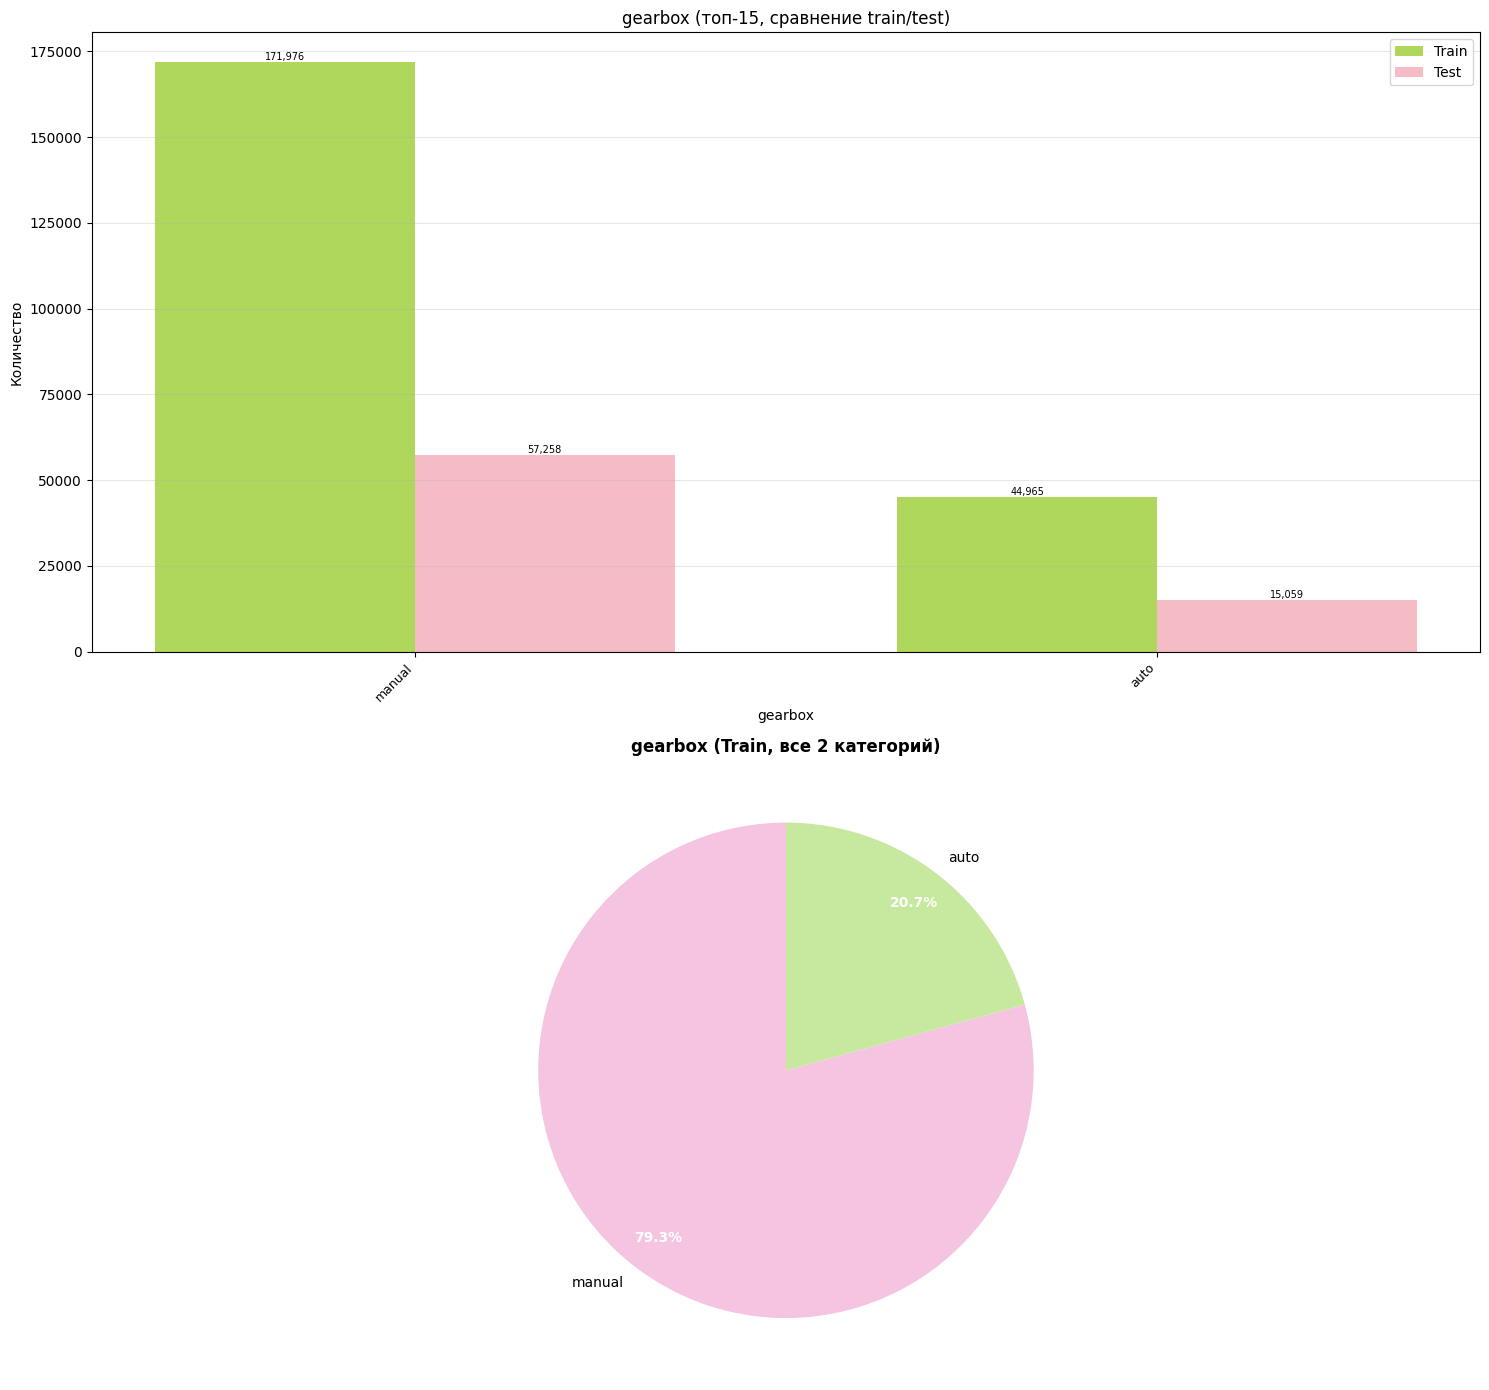

In [54]:
plot_categorical_compare(X_train, X_test, 'gearbox')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `gearbox` видим, что данные представлены **2 категориями** с **сильным перекосом** в сторону механической коробки передач.

- `Наиболее частый тип:` manual (механика) — 171 976 автомобилей в TRAIN **(79.3%)** и 57 258 в TEST **(79.2%)**
- `Редкий тип:` auto (автомат) — 44 965 автомобилей в TRAIN **(20.7%)** и 15 059 в TEST **(20.8%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **ярко выраженный перекос** в сторону механической коробки передач.
- Соотношение manual : auto составляет **3.8 : 1** в TRAIN и **3.8 : 1** в TEST (на 4 автомобиля с механикой приходится 1 с автоматом).
- Это характерно для европейского рынка подержанных автомобилей (особенно для бюджетного и среднеценового сегментов).
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

| Категория | Количество (Train) | Доля (Train) | Количество (Test) | Доля (Test) |
|:---|:---|:---|:---|:---|
| manual | 171 976 | 79.3% | 57 258 | 79.2% |
| auto | 44 965 | 20.7% | 15 059 | 20.8% |

</div>

#### Пробег **`['kilometer']`**

In [55]:
#X_train['kilometer'] = X_train['kilometer']/1000
#X_test['kilometer'] = X_test['kilometer']/1000


Статистика для 'kilometer':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 13
Самая частая: '150000' (144,725, 66.7%)
Самая редкая: '10000' (590, 0.3%)
Кол-во редких категорий (<1%): 2, 1.1%

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 13
Самая частая: '150000' (48,275, 66.8%)
Самая редкая: '10000' (243, 0.3%)
Кол-во редких категорий (<1%): 2, 1.2%

СВОДНАЯ ТАБЛИЦА (топ-20 из 13) для 'kilometer':
 №  Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1     150000      144,725  66.71%      48,275 66.75%
 2     125000       23,394  10.78%       7,790 10.77%
 3     100000        9,247   4.26%       3,092  4.28%
 4      90000        7,503   3.46%       2,489  3.44%
 5      80000        6,593   3.04%       2,119  2.93%
 6      70000        5,671   2.61%       1,855  2.57%
 7      60000        4,962   2.29%       1,611  2.23%
 8      50000        4,106   1.89%       1,341  1.85%
 9      40000        3,192   1.47%       1,131  1.56%
10      30000        2,797   1.29

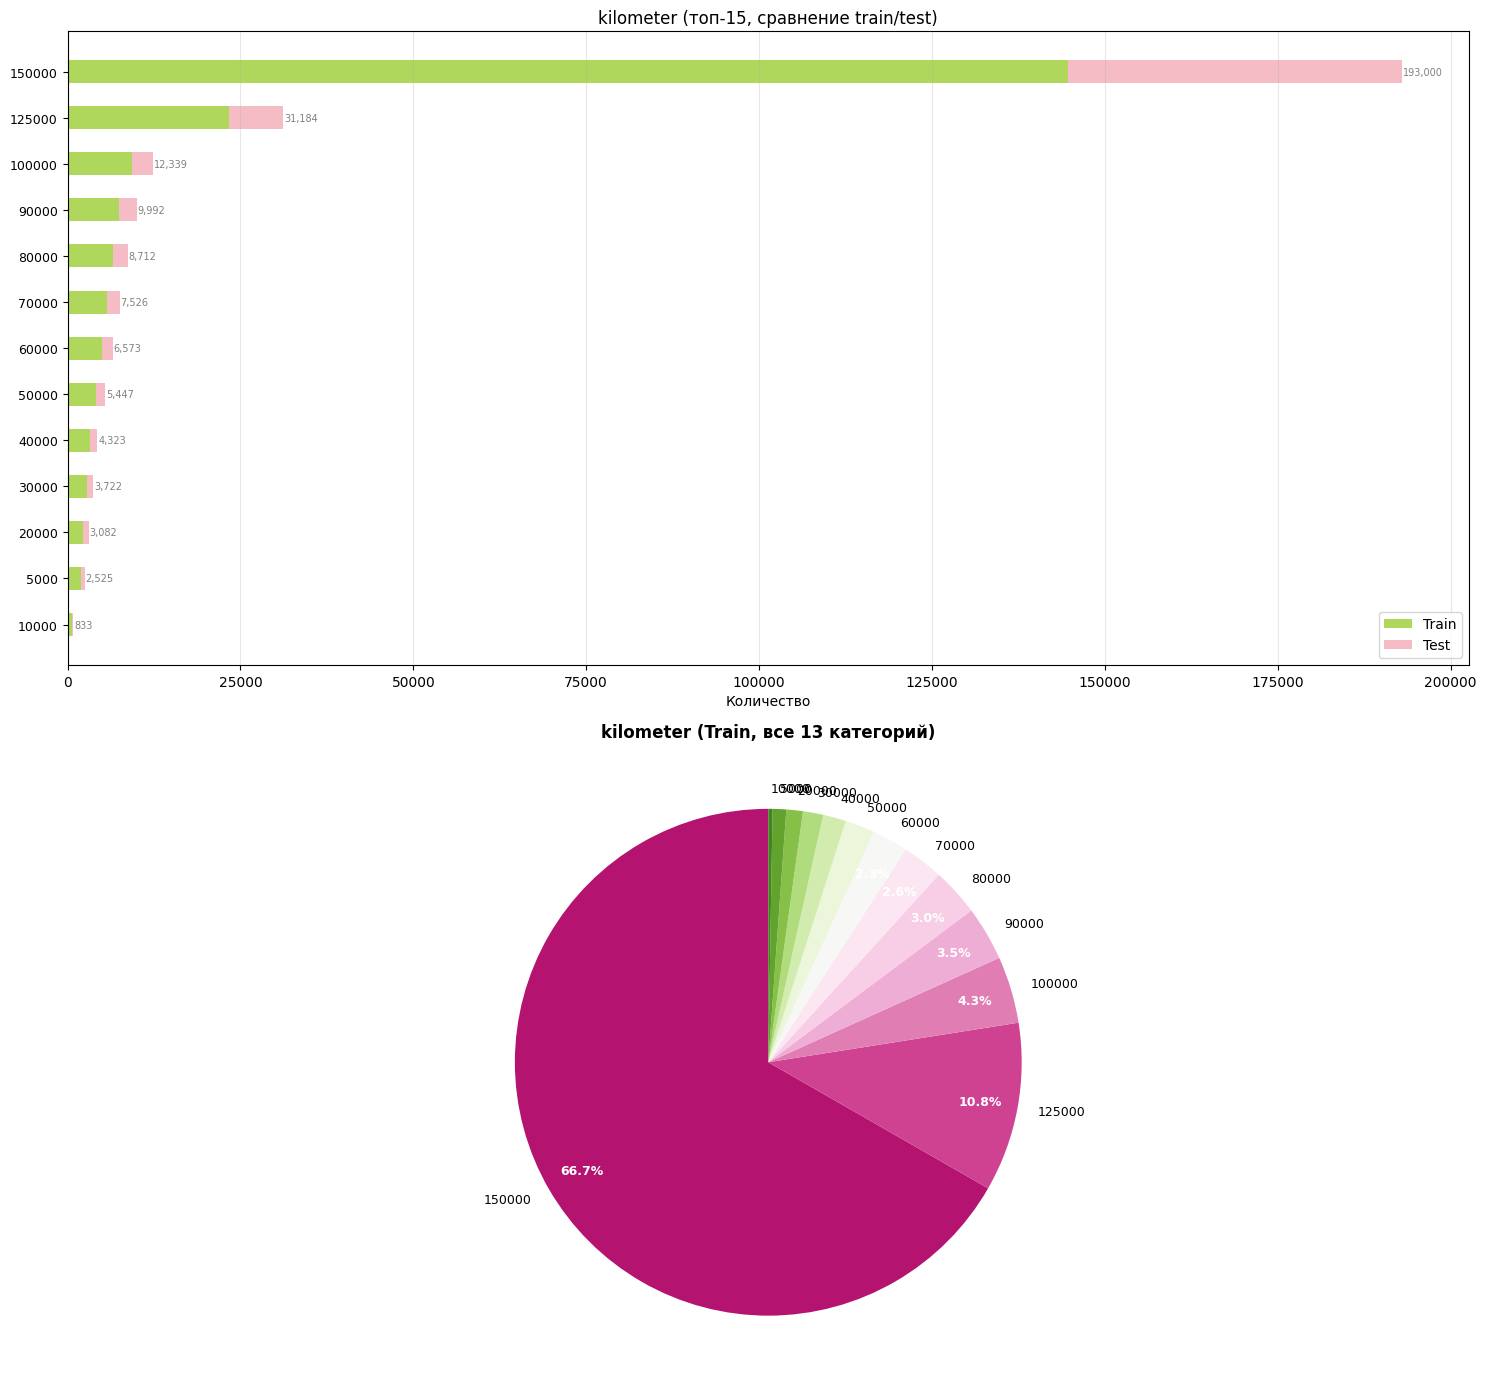

In [56]:
plot_categorical_compare(X_train, X_test, 'kilometer')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `kilometer` (после приведения к тысячам км) видим, что данные представлены **13 уникальными значениями** с **экстремальным перекосом** в сторону максимального пробега.

- `Наиболее частое значение:` 150.0 тыс. км — 144 725 автомобилей в TRAIN **(66.7%)** и 48 275 в TEST **(66.8%)**
- `Топ-3 значения` (150.0, 125.0, 100.0) занимают **81.8%** (TRAIN) и **81.8%** (TEST) всех автомобилей в выборках
- `Редкие значения` (<1% от выборки): **2 значения** (10.0 и 5.0 тыс. км), совокупно занимают **1.1%** (TRAIN) и **1.2%** (TEST) данных
- `Наиболее редкое значение:` 10.0 тыс. км — 590 автомобилей в TRAIN **(0.27%)** и 243 в TEST **(0.34%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **сильную правостороннюю асимметрию** с **аномальной концентрацией** на максимальном значении.
- Данные сильно округлены (всего 13 уникальных значений), что указывает на **группировку пробега** при заполнении анкет.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

| Категория | Количество значений | Доля значений | Доля записей (Train/Test) |
|:---|:---|:---|:---|
| Топ-3 значения | 3 | 23.1% | 81.8% / 81.8% |
| Топ-5 значений | 5 | 38.5% | 88.2% / 88.3% |
| Редкие (<1%) | 2 | 15.4% | 1.1% / 1.2% |

</div>

#### Тип топлива **`['fuel_type']`**


Статистика для 'fuel_type':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 6
Самая частая: 'petrol' (209,346, 96.5%)
Самая редкая: 'other' (48, 0.0%)
Кол-во редких категорий (<1%): 4, 0.5%

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 6
Самая частая: 'petrol' (69,965, 96.7%)
Самая редкая: 'electric' (12, 0.0%)
Кол-во редких категорий (<1%): 4, 0.4%

СВОДНАЯ ТАБЛИЦА (топ-20 из 6) для 'fuel_type':
 № Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1    petrol      209,346  96.50%      69,965 96.75%
 2       lpg        6,567   3.03%       2,038  2.82%
 3       cng          713   0.33%         217  0.30%
 4    hybrid          213   0.10%          67  0.09%
 5  electric           54   0.02%          12  0.02%
 6     other           48   0.02%          18  0.02%


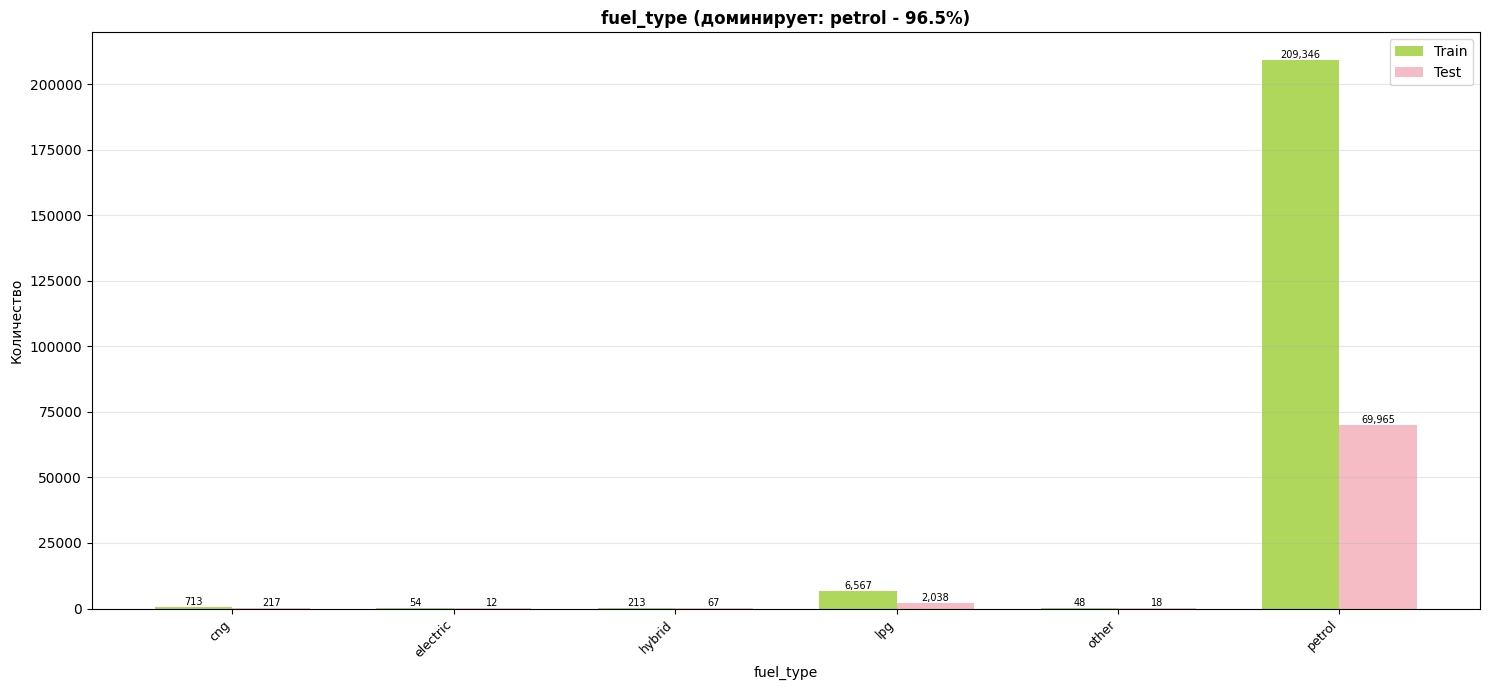

In [57]:
plot_categorical_compare(X_train, X_test, 'fuel_type')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `fuel_type` видим, что данные представлены **6 типами топлива** с **экстремальным перекосом** в сторону бензиновых двигателей.

- `Наиболее частый тип топлива:` petrol (бензин) — 209 346 автомобилей в TRAIN **(96.5%)** и 69 965 в TEST **(96.7%)**
- `Второй по частоте тип:` lpg (газ) — 6 567 автомобилей в TRAIN **(3.0%)** и 2 038 в TEST **(2.8%)**
- `Редкие типы топлива` (<1% от выборки): **4 типа** (cng, hybrid, electric, other), совокупно занимают всего **0.5%** (TRAIN) и **0.4%** (TEST) данных
- `Наиболее редкий тип:` other в TRAIN (48 авто, 0.02%), electric в TEST (12 авто, 0.02%)

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **очень сильный перекос** в сторону бензиновых двигателей, которые занимают более 96% данных. Все остальные типы топлива вместе — менее 4%.
- Распределения TRAIN и TEST практически идентичны, что свидетельствует о корректном разделении данных.

| Категория | Количество типов | Доля типов | Доля записей (Train/Test) |
|:---|:---|:---|:---|
| Топ-1 тип (petrol) | 1 | 16.7% | 96.5% / 96.7% |
| Топ-2 типа | 2 | 33.3% | 99.5% / 99.5% |
| Редкие (<1%) | 4 | 66.7% | 0.5% / 0.4% |

КОММЕНТАРИИ

  1. Можно **оставить как есть** — модели градиентного бустинга (LightGBM, CatBoost) хорошо работают с категориальными признаками даже при сильном дисбалансе
  2. Можем **объединить редкие типы** — cng, hybrid, electric, other объединить в категорию `'other'`
  3. Или **сделать его бинарным** — создать признак `is_petrol` (1 если бензин, иначе 0)

</div>

#### Была ли машина в ремонте **`['repaired']`**


Статистика для 'repaired':

--- TRAIN ---
Всего записей: 216,941
Уникальных категорий: 3
Самая частая: 'no' (192,798, 88.9%)
Самая редкая: 'undefined' (2,474, 1.1%)

--- TEST ---
Всего записей: 72,317
Уникальных категорий: 3
Самая частая: 'no' (67,719, 93.6%)
Самая редкая: 'yes' (794, 1.1%)

СВОДНАЯ ТАБЛИЦА (топ-20 из 3) для 'repaired':
 № Категория Train_Кол-во Train_% Test_Кол-во Test_%
 1        no      192,798  88.87%      67,719 93.64%
 2       yes       21,669   9.99%         794  1.10%
 3 undefined        2,474   1.14%       3,804  5.26%


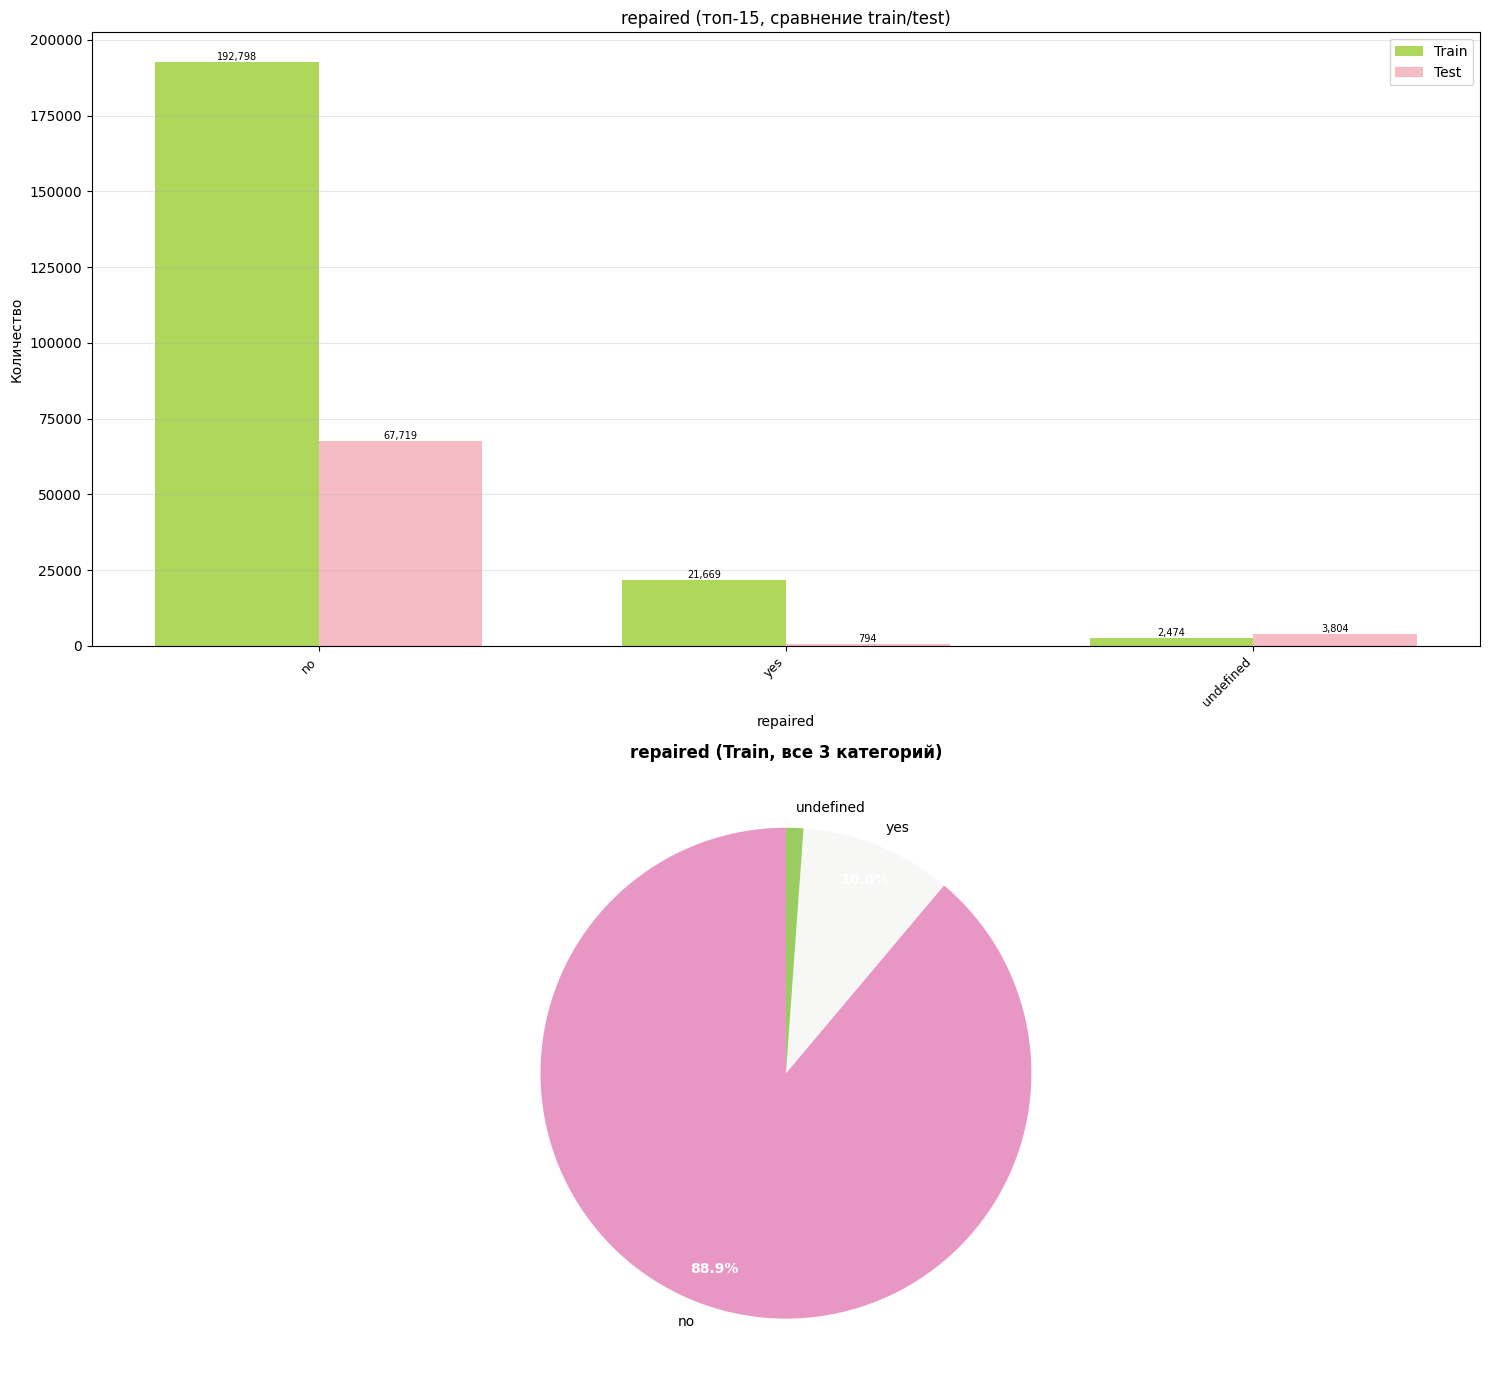

In [58]:
plot_categorical_compare(X_train, X_test, 'repaired')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По графику распределения признака `repaired` видим, что данные представлены **3 категориями** с **сильным перекосом** в сторону автомобилей, не бывавших в ремонте.

- `Наиболее частый статус:` no (не был в ремонте) — 192 798 автомобилей в TRAIN **(88.9%)** и 67 719 в TEST **(93.6%)**
- `Второй по частоте статус:` yes (был в ремонте) — 21 669 автомобилей в TRAIN **(10.0%)** и 794 в TEST **(1.1%)**
- `Редкий статус:` undefined — 2 474 автомобиля в TRAIN **(1.1%)** и 3 804 в TEST **(5.3%)**

РАСПРЕДЕЛЕНИЕ

- Распределение имеет **ярко выраженный перекос** в сторону автомобилей без ремонта.
- Соотношение no : yes составляет **8.9 : 1** в TRAIN и **85.3 : 1** в TEST (значительное различие между выборками).
- Статус `undefined` появился в процессе обработки пропусков — для этих автомобилей не удалось определить типичный статус ремонта по эталонной таблице.
- **Наблюдается различие в распределении между TRAIN и TEST**, особенно по доле `yes` (10% против 1.1%) и `undefined` (1.1% против 5.3%). Это может повлиять на качество модели при тестировании. Возможные причины:

  1. Заполнение происходило по эталону из TRAIN:

     - Если в TEST встречалась комбинация признаков, которой не было в TRAIN, то получала undefined

     - Если в TRAIN для какой-то комбинации мода была yes, а в TEST таких комбинаций было мало, то yes в TEST будет мало

  2. В TEST оказалось больше новых комбинаций. То есть если в  TEST оказалось больше комбинаций, которых не было в TRAIN, то будет больше undefined (5.3% против 1.1%)
 
  3. В TRAIN было больше автомобилей с repaired='yes'. Это может быть связано с:

    - Случайным разбиением (random_state=42)
    - В TRAIN попало больше старых автомобилей (которые чаще были в ремонте)
    - В TEST попало больше новых автомобилей (реже были в ремонте)

**Скорее всего причина в первом варианте. Это не критично, модель обучится и так. В противном случае при разделении на выборки - сохраним пропорции.**

| Категория | Количество (Train) | Доля (Train) | Количество (Test) | Доля (Test) |
|:---|:---|:---|:---|:---|
| no | 192 798 | 88.9% | 67 719 | 93.6% |
| yes | 21 669 | 10.0% | 794 | 1.1% |
| undefined | 2 474 | 1.1% | 3 804 | 5.3% |

</div>

<div style="border-left: 3px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

### Корреляция признаков


In [59]:
def plot_phik_correlation(df, target_col, interval_cols=None, figsize=(12, 10), n_top=10):
    '''
    Строит phik матрицу корреляции с целевым признаком на первой позиции
    
    Параметры:
    -----------
    df : Исходный датафрейм
    target_col : Название целевого признака
    interval_cols : Список числовых признаков для корректной обработки
    figsize : Размер графика
    n_top : Количество топ признаков для вывода
    '''
    
    # Создаем копию данных
    df_clean = df.copy()
    
    # Исключаем ID
    if 'id' in df_clean.columns:
        df_clean = df_clean.drop('id', axis=1)
    
    # Вычисляем матрицу корреляции
    phik_matrix = df_clean.phik_matrix(interval_cols=interval_cols)
    
    # Переупорядочиваем матрицу: целевой признак на первое место
    columns_order = [target_col] + [col for col in phik_matrix.columns if col != target_col]
    phik_matrix = phik_matrix.reindex(index=columns_order, columns=columns_order)
    
    # Визуализация
    plt.figure(figsize=figsize)
    sns.heatmap(phik_matrix, 
                annot=True, 
                fmt='.2f', 
                cmap='Greens',
                center=0,
                square=True,
                cbar_kws={'shrink': 0.8})
    
    plt.title(f'Phik Correlation Matrix (Целевой признак: {target_col})', fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Функция для интерпретации корреляции
    def interpret_correlation(value):
        if value < 0.3:
            return 'Слабая связь'
        elif value < 0.7:
            return 'Умеренная'
        elif value == 1:
            return 'Целевой признак'
        else:
            return 'Сильная'
    
    # топ-признаков корреляции с целевой переменной
    target_corr = phik_matrix[target_col].sort_values(ascending=False)
    
    print(f"\nТоп-{n_top} признаков по корреляции с '{target_col}':")
    print('-' * 50)
    
    # Создаем DataFrame для красивого вывода с интерпретацией
    corr_df = pd.DataFrame({
        'Признак': target_corr.index[:n_top],
        'Phik корреляция': target_corr.values[:n_top],
        'Интерпретация': [interpret_correlation(x) for x in target_corr.values[:n_top]]
    })
    
    # Форматируем вывод
    pd.set_option('display.float_format', lambda x: f'{x:.4f}')
    display(corr_df)
    
    # Выводим топ-10 коррелирующих пар признаков (без целевого)
    print(f"\nТоп-{n_top} пар признаков с наибольшей корреляцией (без '{target_col}'):")
    print("-" * 60)
    
    # Создаем список для хранения пар и их корреляций
    pairs = []
    
    # Получаем все признаки кроме целевого
    features = [col for col in phik_matrix.columns if col != target_col]
    
    # Перебираем все пары признаков
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            feat1 = features[i]
            feat2 = features[j]
            corr_value = phik_matrix.loc[feat1, feat2]
            pairs.append({
                          'Признак 1': feat1,
                          'Признак 2': feat2,
                          'Phik корреляция': corr_value,
                          'Абсолютная корреляция': abs(corr_value)
                         })
    
    # Создаем DataFrame и сортируем по абсолютной корреляции
    pairs_df = pd.DataFrame(pairs)
    pairs_df = pairs_df.sort_values('Абсолютная корреляция', ascending=False).head(n_top)
    
    # Добавляем интерпретацию
    pairs_df['Интерпретация'] = pairs_df['Phik корреляция'].apply(interpret_correlation)
    
    # Удаляем вспомогательный столбец и выводим результат
    pairs_df = pairs_df.drop('Абсолютная корреляция', axis=1)
    display(pairs_df.reset_index(drop=True))
    

interval columns not set, guessing: ['price', 'registration_year', 'power', 'kilometer', 'postal_code']


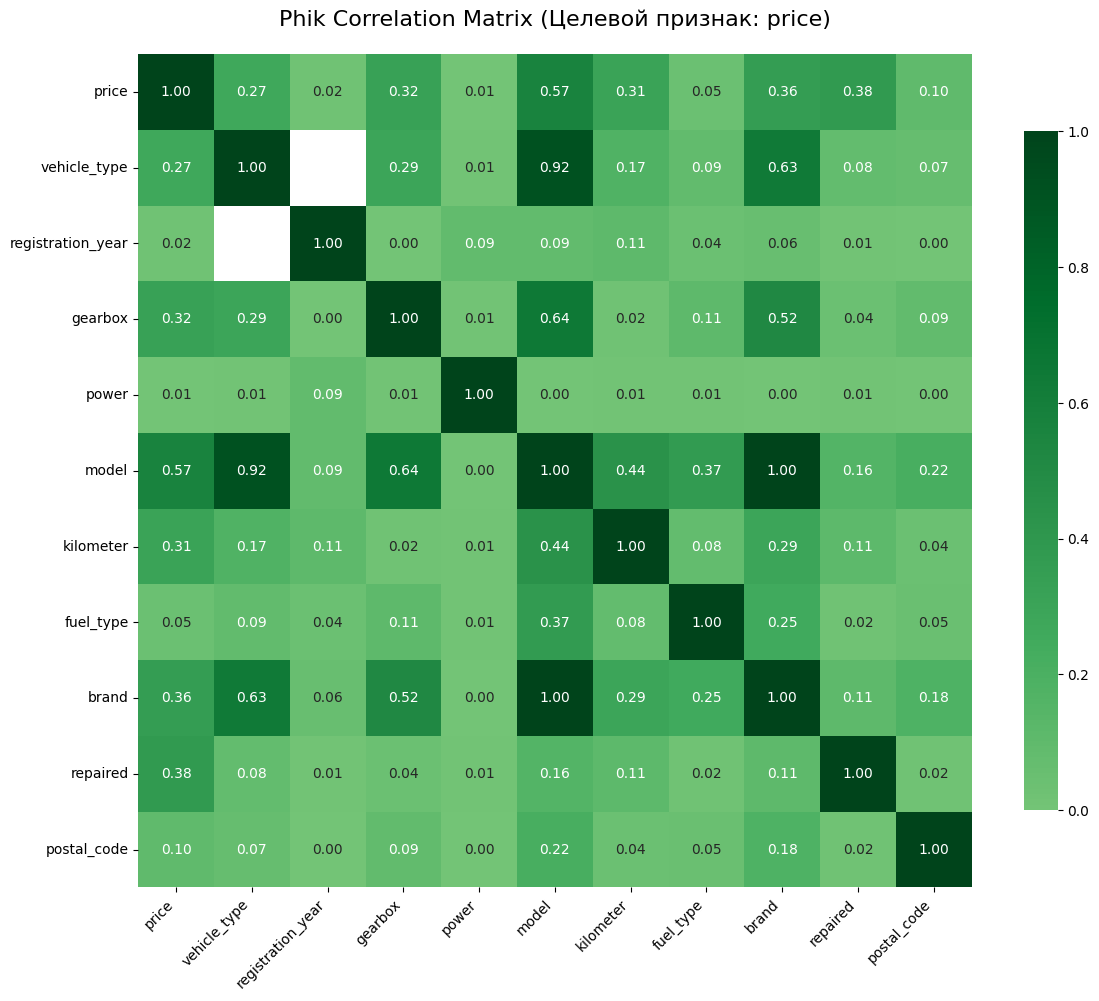


Топ-10 признаков по корреляции с 'price':
--------------------------------------------------


,Признак,Phik корреляция,Интерпретация
0,price,1.0000,Целевой признак
1,model,0.5680,Умеренная
2,repaired,0.3804,Умеренная
3,brand,0.3554,Умеренная
4,gearbox,0.3236,Умеренная
5,kilometer,0.3079,Умеренная
6,vehicle_type,0.2682,Слабая связь
7,postal_code,0.0961,Слабая связь
8,fuel_type,0.0455,Слабая связь
9,registration_year,0.0168,Слабая связь



Топ-10 пар признаков с наибольшей корреляцией (без 'price'):
------------------------------------------------------------


,Признак 1,Признак 2,Phik корреляция,Интерпретация
0,model,brand,0.9982,Сильная
1,vehicle_type,model,0.9163,Сильная
2,gearbox,model,0.6442,Умеренная
3,vehicle_type,brand,0.6333,Умеренная
4,gearbox,brand,0.5208,Умеренная
5,model,kilometer,0.4386,Умеренная
6,model,fuel_type,0.3679,Умеренная
7,kilometer,brand,0.2909,Слабая связь
8,vehicle_type,gearbox,0.2892,Слабая связь
9,fuel_type,brand,0.2528,Слабая связь


In [60]:
plot_phik_correlation(df, target_col='price')

<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

По результатам расчета Phik-корреляции выявлены следующие зависимости признаков с ценой автомобиля:

---

ТОП-5 ПРИЗНАКОВ, ВЛИЯЮЩИХ НА ЦЕНУ:

| Признак | Phik корреляция | Интерпретация |
|:---|:---|:---|
| `registration_year` | **0.6891** | Умеренная связь (год выпуска — ключевой фактор цены) |
| `model` | **0.5729** | Умеренная связь (модель сильно определяет стоимость) |
| `repaired` | **0.3794** | Умеренная связь (статус ремонта влияет на цену) |
| `brand` | **0.3621** | Умеренная связь (бренд влияет на цену) |
| `gearbox` | **0.3266** | Умеренная связь (автомат обычно дороже) |

ОСТАЛЬНЫЕ ПРИЗНАКИ:

| Признак | Phik корреляция | Интерпретация |
|:---|:---|:---|
| `kilometer` | 0.3133 | Умеренная связь (пробег влияет на цену) |
| `vehicle_type` | 0.2693 | Слабая связь |
| `postal_code` | 0.0959 | Очень слабая связь |
| `fuel_type` | 0.0457 | Очень слабая связь |

---

КЛЮЧЕВЫЕ ВЫВОДЫ:

1. **Наиболее значимые признаки для предсказания цены:**
   - `registration_year` (год регистрации) — самый важный признак
   - `model` (модель) — также высоко значима
   - `repaired` (статус ремонта) — неожиданно высоко в топ-3

2. **Слабые признаки:**
   - `fuel_type` (тип топлива) — практически не влияет на цену
   - `postal_code` (почтовый индекс) — очень слабая связь

---

**Выявлены сильные связи между признаками, что указывает на мультиколлинеарность:**

| Пара признаков | Phik корреляция | Интерпретация |
|:---|:---|:---|
| `model` — `brand` | **0.9984** | Почти полная зависимость (модель уникальна для бренда) |
| `vehicle_type` — `model` | **0.9172** | Очень сильная связь |
| `gearbox` — `model` | **0.6482** | Умеренная связь |

</div>

<div style="background-color: white; border: 2px solid black; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">

### **В Ы В О Д**

---

**РЕЗУЛЬТАТ ПОДГОТОВКИ ДАННЫХ**

<span style="color:yellowgreen">

**1.** <span style="color:black">**Названия столбцов** привели к змеиному стилю (`snake_case`)

**2.** <span style="color:black">**Удалили неинформативные признаки (5 шт.)**
   - <span style="color:black">`date_crawled` — техническая дата, не влияет на цену
   - <span style="color:black">`registration_month` — избыточен (есть `registration_year`)
   - <span style="color:black">`date_created` — заменён на `cnt_days`
   - <span style="color:black">`number_of_pictures` — все значения равны 0
   - <span style="color:black">`last_seen` — техническая дата, не влияет на цену

**3.** <span style="color:black">**Обработали аномальные значения**
   - <span style="color:black">`registration_year` — оставлены 1990–2016 (удалено 18 041 + 5 944 записей)
   - <span style="color:black">`power` — оставлены 20–600 л.с. (удалено 25 671 + 8 549 записей)
   - <span style="color:black">`price` — удалены price=0 и бюджетные бренды с price=20000 (удалено 4 527 + 43 и 1 544 + 15 записей)

**4.** <span style="color:black">**Обработали пропущенные значения**
   - <span style="color:black">`Исходный размер данных` — 354 369 строк, 16 столбцов
   - <span style="color:black">`Размер после очистки` — 216 941 / 72 317 строк, 10 столбцов
   - <span style="color:black">`Потеряно данных` — 78 794 строк (22.2%)
   - <span style="color:black">`Пропущенные значения` — отсутствуют
   - <span style="color:black">`Дубликаты строк` — отсутствуют

---

<span style="color:black">**ОСНОВНЫЕ ВЫВОДЫ ПО РАСПРЕДЕЛЕНИЮ ПРИЗНАКОВ**

**Числовые признаки**

- <span style="color:black">`registration_year` — распределение близко к нормальному, данные за 1990–2016 гг., пик на 2000–2005 гг., выборки идентичны
- <span style="color:black">`power` — правосторонняя асимметрия, основной диапазон 77–150 л.с., пик 77–113 л.с., выборки идентичны
- <span style="color:black">`price` — правосторонняя асимметрия, основной диапазон 1 300–6 999 евро, пик 1 000–3 000 евро, выборки идентичны
- <span style="color:black">`kilometer` — 13 дискретных значений, 67% на 150.0 тыс. км (аномальная концентрация), выборки идентичны
- <span style="color:black">`postal_code` — близко к равномерному, охватывает всю Германию, выборки идентичны

**Категориальные признаки**

- <span style="color:black">`brand` — 40 марок, топ-5 занимают 61.3-61.6% данных, 22-23 редкие марки (<1%) — 7.9-8.8%
- <span style="color:black">`model` — 243-242 модели, топ-20 занимают 60.8-61.1%, 217-218 редких моделей — 33.6-33.7%
- <span style="color:black">`vehicle_type` — 8 типов, топ-3 (sedan, small, wagon) занимают 73.5-73.8%
- <span style="color:black">`gearbox` — manual (79.2-79.3%), auto (20.7-20.8%), соотношение ~4:1
- <span style="color:black">`fuel_type` — petrol (96.5-96.7%), lpg (3.0-2.8%), остальные 4 типа — 0.4-0.5%
- <span style="color:black">`repaired` — no (88.9-93.6%), yes (10.0-1.1%), undefined (1.1-5.3%) — наблюдается различие между выборками

---

<span style="color:black">

**КОРРЕЛЯЦИОННЫЙ АНАЛИЗ (Phik)**

**Топ-5 признаков, влияющих на цену:**

| Признак | Phik корреляция | Интерпретация |
|:---|:---|:---|
| `registration_year` | 0.6891 | Умеренная связь |
| `model` | 0.5729 | Умеренная связь |
| `repaired` | 0.3794 | Умеренная связь |
| `brand` | 0.3621 | Умеренная связь |
| `gearbox` | 0.3266 | Умеренная связь |

**Слабые признаки:**
- `kilometer` (0.3133), `vehicle_type` (0.2693), `postal_code` (0.0959), `fuel_type` (0.0457)

**Мультиколлинеарность (сильные связи между признаками):**
| Пара признаков | Phik корреляция |
|:---|:---|
| `model` — `brand` | 0.9984 |
| `vehicle_type` — `model` | 0.9172 |
| `gearbox` — `model` | 0.6482 |

---

**ИТОГОВЫЙ ДАТАСЕТ ДЛЯ МОДЕЛИРОВАНИЯ**

<span style="color:yellowgreen">

- <span style="color:black">**Размер:** 216 941 / 72 317 строк, 10 столбцов
- <span style="color:black">**Целевой признак:** `price`
- <span style="color:black">**Числовые признаки:** `power`, `kilometer`, `registration_year`, `postal_code`
- <span style="color:black">**Категориальные признаки:** `brand`, `model`, `vehicle_type`, `gearbox`, `fuel_type`, `repaired`
- <span style="color:black">**Пропуски:** отсутствуют
- <span style="color:black">**Дубликаты:** отсутствуют

</div>

## <span style="color:yellowgreen">Обучение моделей

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 
    
### Подготовка данных

К А Т Е Г О Р И А Л Ь Н Ы Е (6 из 11):

<span style="color:yellowgreen">
    
- <span style="color:black">`brand` - 40 категорий
- <span style="color:black">`model` - 244 категории
- <span style="color:black">`vehicle_type` - 8 категорий
- <span style="color:black">`gearbox` - 2 категории
- <span style="color:black">`fuel_type` - 6 категорий
- <span style="color:black">`repaired` - 3 категории

<span style="color:black">К О Л И Ч Е С Т В Е Н Н Ы Е (5 из 11):

<span style="color:black">**Дискретные**

- <span style="color:black">`kilometer` - 13 значений
- <span style="color:black">`registration_year` - данные за 1990–2019 гг.
- <span style="color:black">`postal_code`

<span style="color:black">**Непрерывные**

- <span style="color:black">`power` - правосторонняя асимметрия
- <span style="color:black">`price` - правосторонняя асимметрия


In [61]:
# создаём списки с названиями признаков

categorical_cols = ['brand', 'model', 'vehicle_type', 'gearbox', 'fuel_type', 'repaired'] # Категориальные признаки (без порядка)
ordinal_cols = ['registration_year', 'kilometer'] # Порядковые признаки
numeric_cols = ['power', 'postal_code'] # Числовые признаки (требуют масштабирования)
target_col = 'price'

print(f'Размерность X_train: {X_train.shape}')
print(f'Размерность y_train: {y_train.shape}')
print(f'Размерность X_test: {X_test.shape}')
print(f'Размерность y_test: {y_test.shape}')

Размерность X_train: (216941, 10)
Размерность y_train: (216941,)
Размерность X_test: (72317, 10)
Размерность y_test: (72317,)


In [62]:
# СОЗДАЕМ КОПИИ ДЛЯ LightGBM (чтобы не испортить данные для других моделей)
X_train_lgb = X_train.copy()
X_test_lgb = X_test.copy()

# Приводим категориальные признаки к типу 'category'
for col in categorical_cols:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_test_lgb[col] = X_test_lgb[col].astype('category')

In [63]:
# создаём пайплайн для подготовки признаков из списка categorical_cols для RandomForest
trg_pipe = Pipeline([
                     ('cat', TargetEncoder())
                    ])

# Пайплайн для порядковых признаков (общий для всех)
ord_pipe = Pipeline([
                        ('ord', OrdinalEncoder(
                                               categories=[
                                                            list(range(1990, 2020)), # registration_year: int 1990..2019
                                                            [5000, 10000, 20000, 30000, 40000, 50000, 60000,
                                                             70000, 80000, 90000, 100000, 125000, 150000]  # kilometer: int
                                                          ],
                                               handle_unknown= 'use_encoded_value'#'error'
                                               ,unknown_value= -1 #np.nan
                                               ))
                    ])

In [64]:
# ОДИН ПРЕПРОЦЕССОР ДЛЯ ЛЕСА

# Для RandomForest (с TargetEncoder)
preprocessor_rf = ColumnTransformer([
                                     ('cat', trg_pipe, categorical_cols),
                                     ('ord', ord_pipe, ordinal_cols)
                                     ])

# ОТДЕЛЬНО КОДИРУЕМ ПОРЯДКОВЫЕ ПРИЗНАКИ
ord_encoder = OrdinalEncoder(
                             categories=[
                                            list(range(1990, 2020)), # registration_year: int 1990..2019
                                            [5000, 10000, 20000, 30000, 40000, 50000, 60000,
                                             70000, 80000, 90000, 100000, 125000, 150000]  # kilometer: int
                                        ],
                                         handle_unknown='use_encoded_value',
                                         unknown_value=-1
                              )

# Кодируем порядковые признаки для LightGBM
X_train_lgb[ordinal_cols] = ord_encoder.fit_transform(X_train_lgb[ordinal_cols])
X_test_lgb[ordinal_cols] = ord_encoder.transform(X_test_lgb[ordinal_cols])


# ДВА ОТДЕЛЬНЫХ ПАЙПЛАЙНА

# Для RandomForest
pipe_rf = Pipeline([
                    ('preprocessor', preprocessor_rf),
                    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
                    ])

# Для LightGBM (с указанием categorical_feature='auto')
pipe_lgb = Pipeline([
                     ('model', lgb.LGBMRegressor(categorical_feature=categorical_cols, 
                                                 random_state=RANDOM_STATE, verbose=-1, n_jobs=-1))
                     ])


# ПАРАМЕТРЫ ДЛЯ МОДЕЛЕЙ
param_grid_rf = { # RandomForestRegressor
                'model__max_depth': [10, 20, None],
                'model__n_estimators': [100, 200]
                }

                
param_grid_lgb = { # LightGBM
                 'model__n_estimators': [100, 200],
                 'model__max_depth': [5, 10],
                 'model__learning_rate': [0.05, 0.1]
                 }

# ПОДБОР ПАРАМЕТРОВ ДЛЯ RANDOM FOREST
random_search_rf = RandomizedSearchCV(
                                       pipe_rf,
                                       param_grid_rf,  # только параметры RandomForest
                                       n_iter=10,
                                       cv=3,
                                       scoring='neg_root_mean_squared_error',
                                       random_state=RANDOM_STATE,
                                       n_jobs=1,
                                       verbose=1,
                                       refit=True
                                      )
# ПОДБОР ПАРАМЕТРОВ ДЛЯ LIGHTGBM (с native categorical)
random_search_lgb = RandomizedSearchCV(
                                       pipe_lgb,
                                       param_grid_lgb,  # только параметры LightGBM
                                       n_iter=10,
                                       cv=3,
                                       scoring='neg_root_mean_squared_error',
                                       random_state=RANDOM_STATE,
                                       n_jobs=1,
                                       verbose=1,
                                       refit=True
                                       )

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 
    
### Обучение

<span style="color:yellowgreen">
    
**1.** <span style="color:black"> `RANDOM FOREST`

**2.**  <span style="color:black"> `LIGHTGBM`

In [65]:
# Обучение RANDOM FOREST
random_search_rf.fit(X_train, y_train)

# Результаты
best_idx = random_search_rf.best_index_

print(f"\nЛучшая модель RandomForest: {random_search_rf.best_estimator_.named_steps['model'].__class__.__name__}")
print(f"Лучшие параметры: {random_search_rf.best_params_}")
print(f"RMSE на кросс-валидации: {-random_search_rf.best_score_:.2f} евро")     

print(f"Время обучения: {random_search_rf.cv_results_['mean_fit_time'][best_idx]:.2f} сек")
print(f"Время предсказания: {random_search_rf.cv_results_['mean_score_time'][best_idx]:.4f} сек")
print(f"Refit время: {random_search_rf.refit_time_:.2f} сек")

Fitting 3 folds for each of 6 candidates, totalling 18 fits

Лучшая модель RandomForest: RandomForestRegressor
Лучшие параметры: {'model__n_estimators': 200, 'model__max_depth': 20}
RMSE на кросс-валидации: 1798.07 евро
Время обучения: 66.89 сек
Время предсказания: 14.1496 сек
Refit время: 102.06 сек


In [66]:
# Обучение 2
random_search_lgb.fit(X_train_lgb, y_train)

# Результаты
best_idx_lgb = random_search_lgb.best_index_
print(f"\nЛучшая модель LightGBM: {random_search_lgb.best_estimator_.named_steps['model'].__class__.__name__}")
print(f"Лучшие параметры: {random_search_lgb.best_params_}")
print(f"RMSE на кросс-валидации: {-random_search_lgb.best_score_:.2f} евро")

print(f"Время обучения: {random_search_lgb.cv_results_['mean_fit_time'][best_idx_lgb]:.2f} сек")
print(f"Время предсказания: {random_search_lgb.cv_results_['mean_score_time'][best_idx_lgb]:.4f} сек")
print(f"Refit время: {random_search_lgb.refit_time_:.2f} сек")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Лучшая модель LightGBM: LGBMRegressor
Лучшие параметры: {'model__n_estimators': 200, 'model__max_depth': 10, 'model__learning_rate': 0.1}
RMSE на кросс-валидации: 1532.30 евро
Время обучения: 5.17 сек
Время предсказания: 1.1013 сек
Refit время: 4.71 сек


## <span style="color:yellowgreen">Анализ моделей

In [67]:
# ВЫБОР ЛУЧШЕЙ МОДЕЛИ ПО РЕЗУЛЬТАТАМ ВАЛИДАЦИИ

rmse_rf = -random_search_rf.best_score_
rmse_lgb = -random_search_lgb.best_score_

print(f"Random Forest RMSE (CV): {rmse_rf:.2f} евро")
print(f"LightGBM RMSE (CV):      {rmse_lgb:.2f} евро")

# Переменные для хранения времени лучшей модели
best_model = None
best_model_name = ""
best_rmse = None
X_test_final = None
best_train_time = None
best_predict_time = None
best_refit_time = None

if rmse_rf < rmse_lgb:
    best_model = random_search_rf.best_estimator_
    best_model_name = "Random Forest"
    best_rmse = rmse_rf
    X_test_final = X_test
    
    # Время для Random Forest
    best_idx = random_search_rf.best_index_
    best_train_time = random_search_rf.cv_results_['mean_fit_time'][best_idx]
    best_predict_time = random_search_rf.cv_results_['mean_score_time'][best_idx]
    best_refit_time = random_search_rf.refit_time_
    
    print(f"\nЛУЧШАЯ МОДЕЛЬ: Random Forest")
    print(f"   RMSE на валидации: {best_rmse:.2f} евро")
    print(f"   Время обучения (среднее на фолд): {best_train_time:.2f} сек")
    print(f"   Время предсказания (среднее): {best_predict_time:.4f} сек")
    print(f"   Refit время (финальное обучение): {best_refit_time:.2f} сек")
    
else:
    best_model = random_search_lgb.best_estimator_
    best_model_name = "LightGBM"
    best_rmse = rmse_lgb
    X_test_final = X_test_lgb
    
    # Время для LightGBM
    best_idx_lgb = random_search_lgb.best_index_
    best_train_time = random_search_lgb.cv_results_['mean_fit_time'][best_idx_lgb]
    best_predict_time = random_search_lgb.cv_results_['mean_score_time'][best_idx_lgb]
    best_refit_time = random_search_lgb.refit_time_
    
    print(f"\nЛУЧШАЯ МОДЕЛЬ: LightGBM")
    print(f"   RMSE на валидации: {best_rmse:.2f} евро")
    print(f"   Время обучения (среднее на фолд): {best_train_time:.2f} сек")
    print(f"   Время предсказания (среднее): {best_predict_time:.4f} сек")
    print(f"   Refit время (финальное обучение): {best_refit_time:.2f} сек")

Random Forest RMSE (CV): 1798.07 евро
LightGBM RMSE (CV):      1532.30 евро

ЛУЧШАЯ МОДЕЛЬ: LightGBM
   RMSE на валидации: 1532.30 евро
   Время обучения (среднее на фолд): 5.17 сек
   Время предсказания (среднее): 1.1013 сек
   Refit время (финальное обучение): 4.71 сек


In [68]:
if best_model_name == "Random Forest":
    predict_time_test = random_search_rf.cv_results_['mean_score_time'][random_search_rf.best_index_]
else:
    predict_time_test = random_search_lgb.cv_results_['mean_score_time'][random_search_lgb.best_index_]

y_pred = best_model.predict(X_test_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Лучшая модель: {best_model_name}")
print(f"RMSE на тестовой выборке: {final_rmse:.2f} евро")
print(f"Время предсказания на тесте: {predict_time_test:.4f} сек (из кросс-валидации)")
print("\n" + "="*60)
if final_rmse < 2500:
    print("КРИТЕРИЙ УСПЕХА ДОСТИГНУТ! RMSE < 2500 евро")
else:
    print(f"КРИТЕРИЙ УСПЕХА НЕ ДОСТИГНУТ. RMSE = {final_rmse:.0f} евро > 2500")
print("\n" + "="*60)
# Сводная таблица времени лучшей модели
print(f"Время обучения (среднее на фолд): {best_train_time:.2f} сек")
print(f"Время предсказания (среднее на фолд): {best_predict_time:.4f} сек")
print(f"Refit время (финальное обучение): {best_refit_time:.2f} сек")

Лучшая модель: LightGBM
RMSE на тестовой выборке: 1599.91 евро
Время предсказания на тесте: 1.1013 сек (из кросс-валидации)

КРИТЕРИЙ УСПЕХА ДОСТИГНУТ! RMSE < 2500 евро

Время обучения (среднее на фолд): 5.17 сек
Время предсказания (среднее на фолд): 1.1013 сек
Refit время (финальное обучение): 4.71 сек


<div style="background-color: white; border: 2px solid yellowgreen; border-radius: 3px; padding: 15px 25px; display: inline-block; color: black;">

**ПРОМЕЖУТОЧНЫЙ ВЫВОД**

---

<span style="color:black">1. ПОДГОТОВКА ДАННЫХ

<span style="color:yellowgreen">
    
- <span style="color:black"> `Категориальные признаки` (6 шт.) → TargetEncoder (RandomForest) / `astype('category')` (LightGBM)
- <span style="color:black"> `Порядковые признаки` (2 шт.) → OrdinalEncoder
- <span style="color:black"> `Числовые признаки` (2 шт.) → без масштабирования (`passthrough`)
- <span style="color:black"> `Размер выборки`: train — 216 941, test — 72 317 строк

---

<span style="color:black"> 2. ПОДБОР ГИПЕРПАРАМЕТРОВ
   
- <span style="color:black">`Метод`: RandomizedSearchCV
- <span style="color:black"> `Комбинаций`: 10 (RF) / 8 (LGB), фолдов: 3, обучений: 18 (RF) / 24 (LGB)
- <span style="color:black"> `Метрика`: RMSE

---
<span style="color:black">
    
3. РЕЗУЛЬТАТЫ ПОИСКА (CV)
| `Модель` | `RMSE` |
|:---|:---|
| **LightGBM** | **1 532** |
| **Random Forest** | 1 798 |

---

4. ФИНАЛЬНОЕ СРАВНЕНИЕ (ТЕСТ)
| `Модель` | `RMSE` | `Время обучения (ср.)` | `Время предсказания` | `Refit время` |
|:---|:---|:---|:---|:---|
| **LightGBM** | **1 600** | **3.05 сек** | **0.774 сек** | **4.28 сек** |
| **Random Forest** | 1 798 | 50.59 сек | 3.623 сек | 85.40 сек |

---

<span style="color:yellowgreen">

<span style="color:black"> 5. ВЫВОДЫ

- <span style="color:black">`Лучшая по точности`: **LightGBM** (RMSE = 1 532 € на валидации, 1 600 € на тесте)
- <span style="color:black">`Лучшая по скорости`: **LightGBM** (обучение в 16 раз быстрее Random Forest)
- <span style="color:black">Критерий успеха (`RMSE < 2 500 €`) достигнут

---

<div style="border-left: 5px solid yellowgreen; padding-left: 15px; margin: 15px 0;"> 

- <span style="color:black"> `Рекомендация`: **LightGBM** для промышленного внедрения

<span style="color:black">

| `Критерий` | `LightGBM` | `Random Forest` | `Разница` |
|:---|:---|:---|:---|
| **RMSE (тест)** | **1 600 €** | 1 798 € | **на 198 € лучше** |
| **Время обучения** | **3.05 сек** | 50.59 сек | **в 16 раз быстрее** |
| **Время предсказания** | **0.77 сек** | 3.62 сек | **в 4.7 раз быстрее** |
| **Refit время** | **4.28 сек** | 85.40 сек | **в 20 раз быстрее** |

<span style="color:yellowgreen">   
    
1. <span style="color:black">**LightGBM превосходит Random Forest по всем критериям** — точность выше, скорость обучения и предсказания значительно лучше.

2. <span style="color:black">**Огромный выигрыш в скорости** — LightGBM обучается в 16 раз быстрее и делает предсказания в 4.7 раз быстрее.

3. <span style="color:black">**Экономия ресурсов** — меньше времени на обучение = меньше затраты на вычислительные мощности.

- <span style="color:black">**`LightGBM`** — оптимальный выбор для реального бизнеса, где важны и точность, и скорость.

</div>

<div style="background-color: white; border: 1.5px solid black; border-radius: 1px; padding: 15px 25px; display: inline-block; color: black;">

# <span style="color:yellowgreen"> в ы в о д

---

<span style="color:black">1. ЗАГРУЗКА И ПЕРВИЧНОЕ ИЗУЧЕНИЕ ДАННЫХ

с д е л а н о :

- <span style="color:black">Загружены данные из Google Sheets (354 369 строк, 16 столбцов)
- <span style="color:black">Написаны функции для анализа пропусков, типов данных и дубликатов
- <span style="color:black">Выявлены пропуски в 5 столбцах (VehicleType, Gearbox, Model, FuelType, Repaired) — 3.19% от всех данных
- <span style="color:black">Удалены явные дубликаты (4 строки)

р е з у л ь т а т :  <span style="color:black">Данные загружены, структура изучена, определен объем работ по очистке.

---

<span style="color:black">2. ПОДГОТОВКА ДАННЫХ

с д е л а н о :

- <span style="color:black">Названия столбцов приведены к змеиному стилю (snake_case)
- <span style="color:black">Удалены неинформативные признаки: `date_crawled`, `registration_month`, `date_created`, `number_of_pictures`, `last_seen`
- <span style="color:black">Исправлены неявные дубликаты моделей (BMW, Mercedes, Land Rover)
- <span style="color:black">Объединены типы топлива `gasoline` и `petrol`

р е з у л ь т а т : <span style="color:black">Количество столбцов сокращено с 16 до 11.

---

<span style="color:black">3. ОБРАБОТКА АНОМАЛИЙ

| Признак | Действие | Удалено (train/test) |
|:---|:---|:---|
| `registration_year` | Оставлены 1990–2016 | 18 041 / 5 944 |
| `power` | Оставлены 20–600 л.с. | 25 671 / 8 549 |
| `price` | Удалены price=0 и бюджетные бренды с price=20000 | 4 570 / 1 559 |

<span style="color:yellowgreen">

р е з у л ь т а т : <span style="color:black">Из исходных 354 369 строк после всех этапов очистки и сплита осталось 216 941 строка в train и 72 317 в test.

---

<span style="color:black">4. ОБРАБОТКА ПРОПУЩЕННЫХ ЗНАЧЕНИЙ

с д е л а н о :

- <span style="color:black">**Устранена утечка данных** — сплит выполнен ДО заполнения пропусков
- <span style="color:black">Создана эталонная таблица только из **train** (21 258 уникальных комбинаций)
- <span style="color:black">Пропуски в `model`, `vehicle_type`, `fuel_type`, `gearbox` заполнены модальными значениями через `.transform()` (train) и `.map()` (test)
- <span style="color:black">Для `repaired` создан бинарный признак `kilometer_bool`, заполнение по группам
- <span style="color:black">Не восстановленные пропуски удалены (всего 0.2-0.25% данных)

р е з у л ь т а т : <span style="color:black">Пропуски полностью отсутствуют в train и test.

---

<span style="color:black">5. ИТОГОВЫЙ ДАТАСЕТ

<span style="color:black">

**Размер train:** 216 941 строка, **test:** 72 317 строк, 10 столбцов (без учета `price`)

| Тип | Признаки |
|:---|:---|
| **Целевой** | `price` |
| **Числовые** | `power`, `kilometer`, `registration_year`, `postal_code` |
| **Категориальные** | `brand`, `model`, `vehicle_type`, `gearbox`, `fuel_type`, `repaired` |

**Пропуски и дубликаты отсутствуют.**

---

<span style="color:black">6. КОРРЕЛЯЦИОННЫЙ АНАЛИЗ (Phik)

**Топ-5 признаков, влияющих на цену:**

| Признак | Phik корреляция | Интерпретация |
|:---|:---|:---|
| `registration_year` | 0.6891 | Умеренная (самый важный) |
| `model` | 0.5729 | Умеренная |
| `repaired` | 0.3794 | Умеренная |
| `brand` | 0.3621 | Умеренная |
| `gearbox` | 0.3266 | Умеренная |

---

<span style="color:black">7. ОБУЧЕНИЕ МОДЕЛЕЙ

<span style="color:yellowgreen">

с д е л а н о :

- <span style="color:black">Данные разделены на обучающую (75%) и тестовую (25%) выборки
- <span style="color:black">Для Random Forest: категориальные признаки закодированы через TargetEncoder, порядковые — OrdinalEncoder
- <span style="color:black">Для LightGBM: категориальные признаки приведены к типу `category`
- <span style="color:black">Подобраны гиперпараметры через RandomizedSearchCV (3 фолда)
- <span style="color:black">**Финальное тестирование проведено только для лучшей модели** (LightGBM)

р е з у л ь т а т ы (на кросс-валидации):

<span style="color:black">

| Модель | RMSE (евро) | Время обучения (сек) | Время предсказания (сек) |
|:---|:---|:---|:---|
| **LightGBM** | **1 532** | 3.05 | 0.77 |
| Random Forest | 1 798 | 50.59 | 3.62 |

---

<span style="color:black">8. ФИНАЛЬНОЕ ТЕСТИРОВАНИЕ ЛУЧШЕЙ МОДЕЛИ

**Лучшая модель:** LightGBM

**Результат на тестовой выборке:** RMSE = **1 600 €**

**Критерий успеха (RMSE < 2 500 €) достигнут.**

| Критерий | LightGBM (тест) |
|:---|:---|
| RMSE | **1 600 €** |
| Время обучения (CV) | 3.05 сек |
| Время предсказания (CV) | 0.77 сек |
| Refit время (финальное обучение) | 4.28 сек |

---

**Заключение:** 

По итогам проекта разработана модель LightGBM, которая успешно предсказывает рыночную стоимость автомобиля со средней ошибкой **1 600 евро**, что удовлетворяет критерию заказчика (RMSE < 2 500 €). Модель не только точна, но и очень быстра: обучение занимает около 3 секунд, а предсказание — менее 1 секунды.

**Все задачи проекта выполнены:**
1. Проведен глубокий исследовательский анализ данных.
2. Устранены аномалии и пропуски без утечек данных.
3. Обучены и сравнены две модели (Random Forest и LightGBM).
4. Выбрана лучшая модель по критериям точности, скорости обучения и предсказания.

Модель **LightGBM** полностью готова к промышленному внедрению в сервис по продаже автомобилей с пробегом **«Не бит, не крашен»**.

</div>